# <div align="right"><span style="color:lightgrey">Université Paul Sabatier - 2025 - Projet</span></div>

# Projet : TER


---
- **Diallo Moussa**

---


---
### $$\text{Projet  : Visualisation d'un réseau de neurones }$$


Il s'agit de produire un petit logiciel de visualisation (en python) qui permet d'illustrer de façon claire et intelligible les transformations des données effectuées par un réseau de neurone pour arriver à un résultat (ou une classification)



---

<br><br>

<font color="blue ">On commence par  installer puis importer les bibliothèques necessaire pour tout le document :</font>


In [ ]:
!pip install tensorflow matplotlib pillow

In [ ]:
# Imports de base
import numpy as np
import matplotlib.pyplot as plt
from IPython.core.debugger import set_trace
import warnings
warnings.filterwarnings('ignore')

# Imports machine learning
from IPython.display import Image, display
import pandas as pd
from sklearn.linear_model import Perceptron
from sklearn import datasets
from sklearn.datasets import make_blobs, make_moons, make_circles, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from matplotlib.colors import ListedColormap

# Imports deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Reshape, Input
from PIL import Image

# Imports PyTorch (pour TER-KHA)
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets as torch_datasets, transforms
import torchvision

# Imports utilitaires
import os
import time
import copy
import math
import pickle
import random as rd
from datetime import datetime

# Configuration des seeds pour reproductibilité
rd.seed(0)
np.random.seed(0)
torch.manual_seed(0)

<br><br>


<h1 style="color:blue; font-size:32px;">
CHAPITRE 1: FONDEMENTS THÉORIQUES
</h1>



Un réseau de neurones est un modèle inspiré du cerveau humain, utilisé pour apprendre des relations complexes entre des données.

# Structure d’un Réseau de Neurones

Un réseau de neurones est un modèle inspiré du fonctionnement du cerveau humain. Il est capable d’apprendre à partir de données en établissant des relations complexes entre les entrées et les sorties.

---

## 📌 Neurone Artificiel

Un neurone artificiel est l’unité de base d’un réseau de neurones. Il réalise deux étapes principales :

- **Calcul d’une somme pondérée** des entrées :

  $$ z = \sum_{i=1}^{n} w_i x_i + b $$

- **Application d'une fonction d'activation** pour produire la sortie :

  $$ y = f(z) $$

*Le schéma du neurone artificiel sera affiché dans la cellule suivante.*

---

## 📌 Architecture d’un Réseau de Neurones

Un réseau de neurones est constitué de plusieurs couches :

1. **Couche d’entrée** : reçoit les données d’entrée.
2. **Couches cachées** : effectuent le traitement et l’apprentissage.
3. **Couche de sortie** : produit le résultat final.

*Le schéma du réseau multicouche sera affiché dans la cellule suivante.*


Affichage de : reseaux_img-1.png


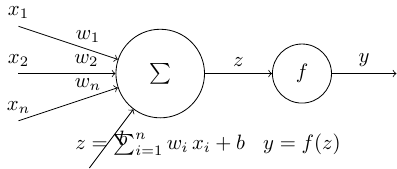

In [ ]:
# 1) (Optionnel, à décommenter si nécessaire) Installer LaTeX & poppler-utils :
# !apt-get install -y texlive-latex-base texlive-latex-extra texlive-pictures poppler-utils

# 2) Générer le source LaTeX
latex_source = r"""
\documentclass{standalone}
\usepackage{tikz}
\begin{document}

% Exemple de neurone artificiel
\begin{tikzpicture}[scale=0.8,
  neuron/.style={circle,draw,minimum size=1cm},
  sum/.style={circle,draw,minimum size=1.5cm}
]
  \node[sum] (N) at (0,0) {$\sum$};
  \node[neuron] (F) at (3,0) {$f$};

  \draw[->] (-3,1) -- node[above,pos=0.7] {$w_1$} node[above,pos=0] {$x_1$} (N);
  \draw[->] (-3,0) -- node[above,pos=0.7] {$w_2$} node[above,pos=0] {$x_2$} (N);
  \draw[->] (-3,-1) -- node[above,pos=0.7] {$w_n$} node[above,pos=0] {$x_n$} (N);
  \draw[->] (-1.5,-2) -- node[right] {$b$} (N);
  \draw[->] (N) -- node[above] {$z$} (F);
  \draw[->] (F) -- node[above] {$y$} ++(2,0);

  \node at (0,-1.5) {$z = \sum_{i=1}^n w_i\,x_i + b$};
  \node at (3,-1.5) {$y = f(z)$};
\end{tikzpicture}

\end{document}
"""

with open("reseaux.tex", "w") as f:
    f.write(latex_source)

# 3) Compiler en PDF
import subprocess
subprocess.run(["pdflatex", "-interaction=nonstopmode", "reseaux.tex"], check=True)

# 4) Convertir PDF → PNG(s)
subprocess.run(["pdftoppm", "-png", "reseaux.pdf", "reseaux_img"], check=True)

# 5) Afficher tous les PNG générés
import os
from IPython.display import Image, display

png_files = sorted(fn for fn in os.listdir('.') if fn.startswith("reseaux_img-") and fn.endswith(".png"))
if not png_files:
    raise FileNotFoundError("Aucun fichier 'reseaux_img-*.png' trouvé. Vérifiez la compilation.")
for fn in png_files:
    print("Affichage de :", fn)
    display(Image(filename=fn))

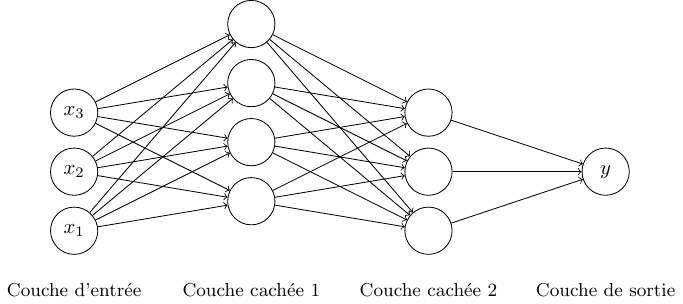

In [ ]:
# (Optionnel : installer LaTeX + poppler-utils une seule fois)
# !apt-get install -y texlive-latex-base texlive-latex-extra texlive-pictures poppler-utils > /dev/null

# 1) Source LaTeX TikZ pour le réseau multicouche
latex_code = r"""
\documentclass{standalone}
\usepackage{tikz}
\usepackage[margin=1in]{geometry}
\begin{document}

\begin{tikzpicture}[
  neuron/.style={circle,draw,minimum size=0.8cm},
  layer/.style={rectangle,draw=none,font=\small}
]
  % Couche d'entrée
  \foreach \y in {1,2,3} {
    \node[neuron] (i\y) at (0,\y) {$x_{\y}$};
  }
  \node[layer] at (0,0) {Couche d’entrée};

  % Couche cachée 1
  \foreach \y in {1,2,3,4} {
    \node[neuron] (h1\y) at (3,\y+0.5) {};
  }
  \node[layer] at (3,0) {Couche cachée 1};

  % Couche cachée 2
  \foreach \y in {1,2,3} {
    \node[neuron] (h2\y) at (6,\y) {};
  }
  \node[layer] at (6,0) {Couche cachée 2};

  % Sortie
  \node[neuron] (o1) at (9,2) {$y$};
  \node[layer] at (9,0) {Couche de sortie};

  % Connexions
  \foreach \i in {1,2,3}{
    \foreach \j in {1,2,3,4}{
      \draw[->] (i\i) -- (h1\j);
    }
  }
  \foreach \i in {1,2,3,4}{
    \foreach \j in {1,2,3}{
      \draw[->] (h1\i) -- (h2\j);
    }
  }
  \foreach \i in {1,2,3}{
    \draw[->] (h2\i) -- (o1);
  }
\end{tikzpicture}
\end{document}
"""

# 2) Sauvegarder et compiler
with open("mlp.tex", "w") as f:
    f.write(latex_code)

import subprocess
subprocess.run(["pdflatex", "-interaction=nonstopmode", "mlp.tex"], check=True)

# 3) Convertir en PNG
subprocess.run(["pdftoppm", "-png", "mlp.pdf", "mlp_img"], check=True)

# 4) Afficher le résultat
import os
from IPython.display import Image, display

for fn in sorted(f for f in os.listdir('.') if f.startswith("mlp_img-") and f.endswith(".png")):
    display(Image(filename=fn))

=== Fonction Sigmoïde ===
σ(z) = 1 / (1 + e^(-z))
Propriétés :
- Sortie dans l'intervalle (0, 1)
- Dérivée : σ'(z) = σ(z)(1 - σ(z))
- Problème : gradient qui disparaît

=== Fonction ReLU ===
ReLU(z) = max(0, z)
Propriétés :
- Simple à calculer
- Dérivée : 1 si z > 0, 0 sinon
- Résout partiellement le problème du gradient disparu

=== Fonction Tanh ===
tanh(z) = (e^z - e^(-z)) / (e^z + e^(-z))
Propriétés :
- Sortie dans (-1, 1)
- Centrée autour de zéro


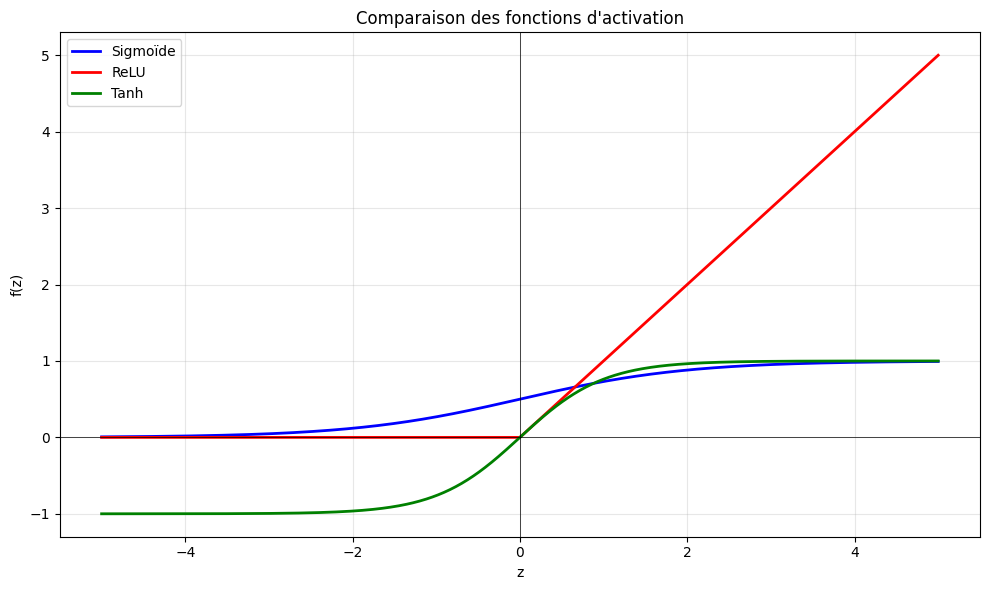

In [ ]:
# Activation functions and visualization in Python
import numpy as np
import matplotlib.pyplot as plt

# Définition des fonctions d'activation
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

def tanh(z):
    return np.tanh(z)

# Texte explicatif simulant les sous-sections LaTeX
def afficher_description():
    print("=== Fonction Sigmoïde ===")
    print("σ(z) = 1 / (1 + e^(-z))")
    print("Propriétés :")
    print("- Sortie dans l'intervalle (0, 1)")
    print("- Dérivée : σ'(z) = σ(z)(1 - σ(z))")
    print("- Problème : gradient qui disparaît\n")

    print("=== Fonction ReLU ===")
    print("ReLU(z) = max(0, z)")
    print("Propriétés :")
    print("- Simple à calculer")
    print("- Dérivée : 1 si z > 0, 0 sinon")
    print("- Résout partiellement le problème du gradient disparu\n")

    print("=== Fonction Tanh ===")
    print("tanh(z) = (e^z - e^(-z)) / (e^z + e^(-z))")
    print("Propriétés :")
    print("- Sortie dans (-1, 1)")
    print("- Centrée autour de zéro")

# Visualisation
def tracer_fonctions_activation():
    z = np.linspace(-5, 5, 1000)

    plt.figure(figsize=(10, 6))
    plt.plot(z, sigmoid(z), label="Sigmoïde", color='blue', linewidth=2)
    plt.plot(z, relu(z), label="ReLU", color='red', linewidth=2)
    plt.plot(z, tanh(z), label="Tanh", color='green', linewidth=2)

    plt.title("Comparaison des fonctions d'activation")
    plt.xlabel("z")
    plt.ylabel("f(z)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.axhline(0, color='black', linewidth=0.5)
    plt.axvline(0, color='black', linewidth=0.5)
    plt.tight_layout()
    plt.show()

# Appel des fonctions
afficher_description()
tracer_fonctions_activation()


<br><br>


<h1 style="color:blue; font-size:32px;">
CHAPITRE 1: LE PERCEPTRON SIMPLE
</h1>


Implémentation du Perceptron Simple
    
    Théorie:
    Le perceptron est un modèle de neurone artificiel qui effectue une
    combinaison linéaire de ses entrées: ŷ = w^T x + b
    
    Pour la classification binaire: sortie = sign(w^T x + b)
    
    Algorithme d'apprentissage:
    1. Initialiser w = 0
    2. Pour chaque exemple mal classé:
       w ← w + y * x (où y ∈ {-1, +1})
    3. Répéter jusqu'à convergence
    """

In [ ]:
class Perceptron:
    def __init__(self, add_bias=True, max_iters=10000, record_updates=False):
        self.max_iters = max_iters
        self.add_bias = add_bias
        self.record_updates = record_updates
        if record_updates:
            self.w_hist = []  # enregistre les poids
            self.n_hist = []  # enregistre l'indice du point de données sélectionné

    def fit(self, x, y):
        if x.ndim == 1:
            x = x[:, None]
        if self.add_bias:
            N = x.shape[0]
            x = np.column_stack([x, np.ones(N)])  # ajout d'un biais (colonne de 1)
        N, D = x.shape
        w = np.zeros(D)  # initialisation des poids à zéro
        if self.record_updates:
            w_hist = [w]

        y = 2 * y - 1  # conversion de 0,1 vers -1,+1
        t = 0
        change = True  # si les poids ne changent plus, l'algorithme a convergé

        while change and t < self.max_iters:
            change = False
            for n in np.random.permutation(N):
                yh = np.sign(np.dot(x[n, :], w))  # prédiction du point d'entraînement
                if yh == y[n]:
                    continue  # on ignore les points bien classés
                w = w + y[n] * x[n, :]
                if self.record_updates:
                    self.w_hist.append(w.copy())
                    self.n_hist.append(n)
                change = True
                t += 1
                if t >= self.max_iters:
                    break

        if change:
            print(f'pas convergé après {t} mises à jour')
        else:
            print(f'convergence après {t} itérations !')

        self.w = w
        return self

    def predict(self, x):
        if x.ndim == 1:
            x = x[:, None]
        Nt = x.shape[0]
        if self.add_bias:
            x = np.column_stack([x, np.ones(Nt)])  # ajout du biais si demandé
        yh = np.sign(np.dot(x, self.w.T))
        return (yh + 1) // 2  # conversion de -1/+1 vers les classes 0/1

Convergence de l’Algorithme Perceptron

Génération de convergence_separable.png...
convergence après 4 itérations !


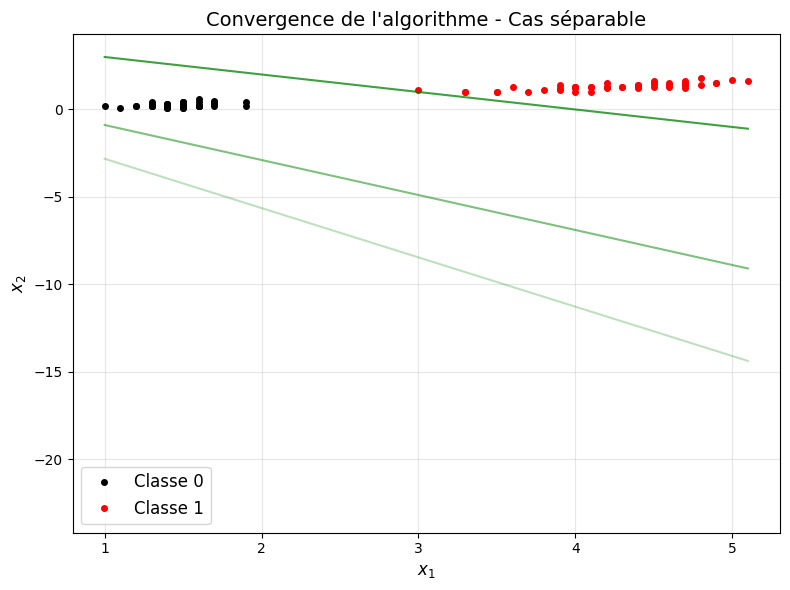

Cas séparable - Nombre de mises à jour: 4

Génération de convergence_non_separable.png...
pas convergé après 10000 mises à jour


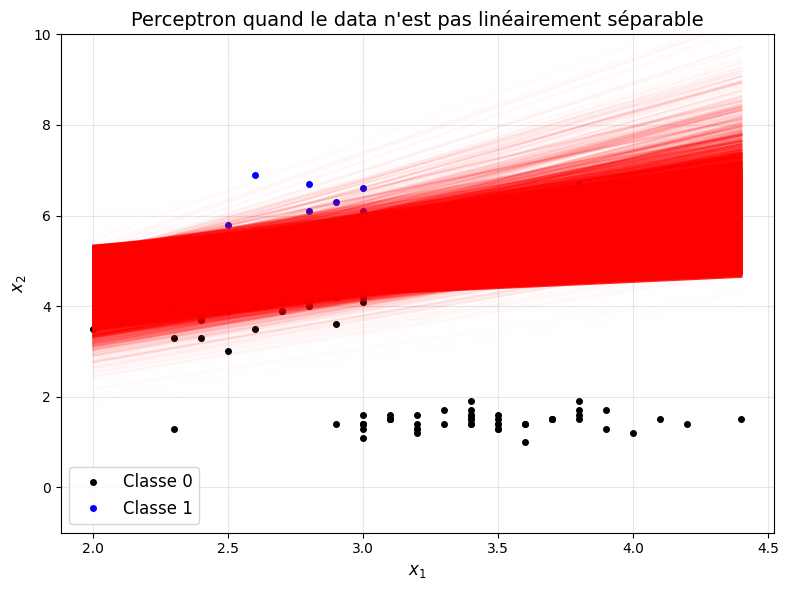

Cas non séparable - Nombre de mises à jour: 10000

Génération de la figure de comparaison...
convergence après 7 itérations !
pas convergé après 10000 mises à jour


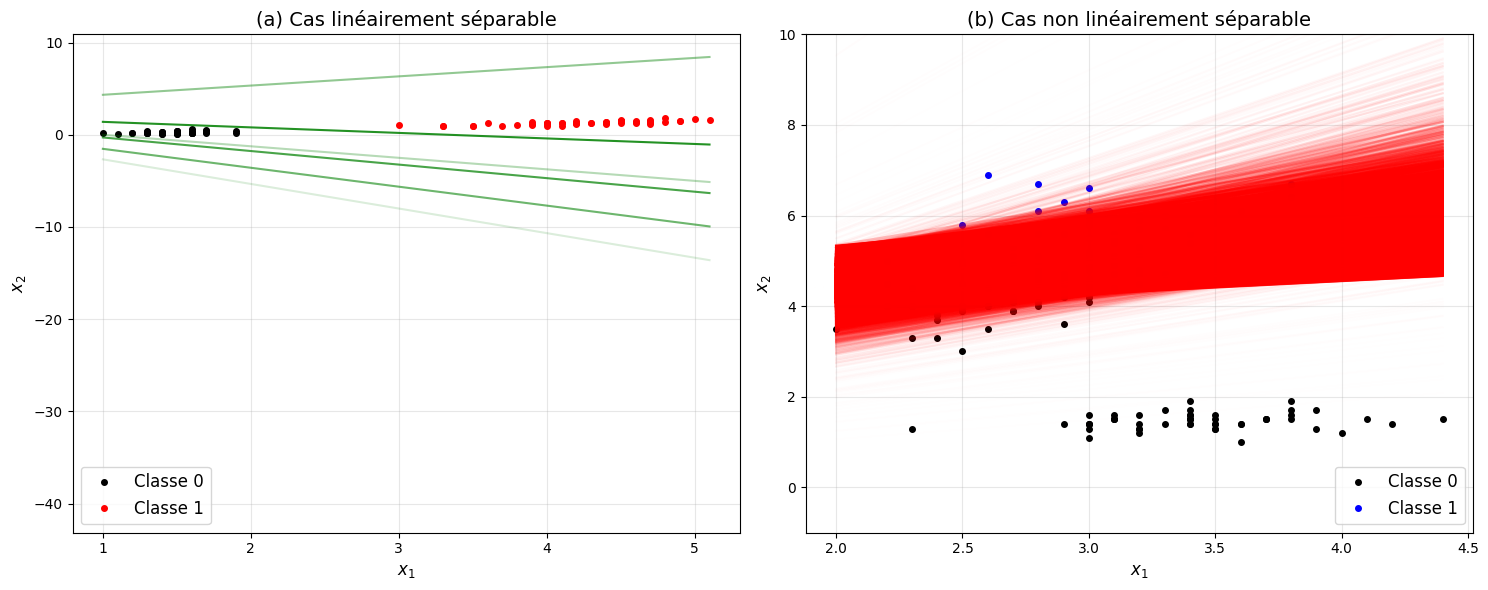

Comparaison - Séparable: 7 mises à jour
Comparaison - Non séparable: 10000 mises à jour
Génération de convergence_separable.png...
convergence après 11 itérations !


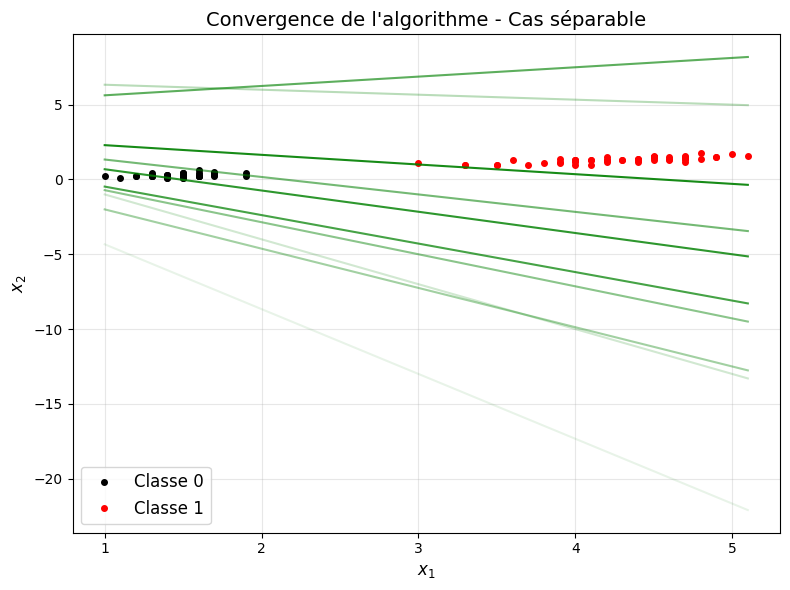

Cas séparable - Nombre de mises à jour: 11

Génération de convergence_non_separable.png...
pas convergé après 10000 mises à jour


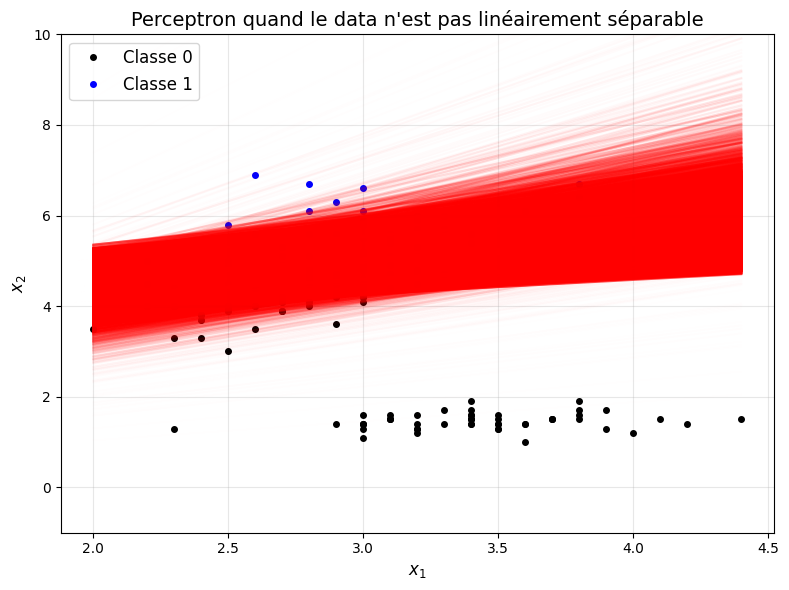

Cas non séparable - Nombre de mises à jour: 10000

Génération de la figure de comparaison...
convergence après 11 itérations !
pas convergé après 10000 mises à jour


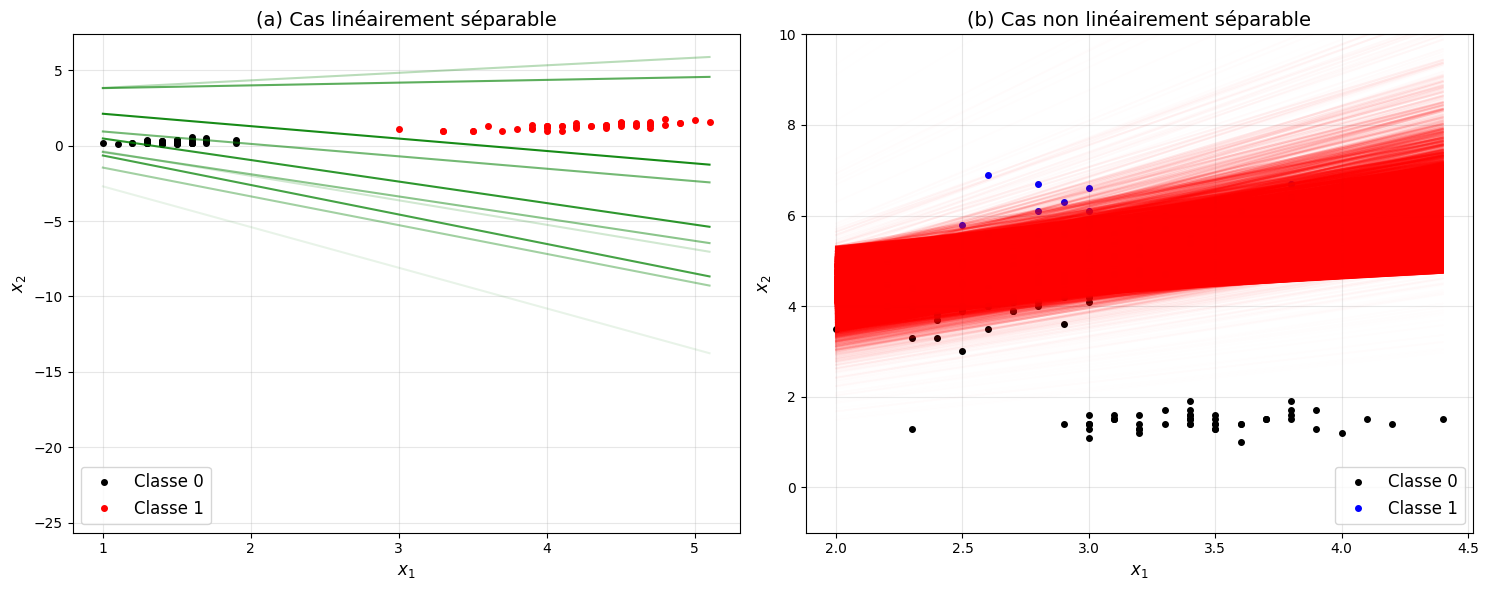

Comparaison - Séparable: 11 mises à jour
Comparaison - Non séparable: 10000 mises à jour


In [ ]:
# Code pour générer convergence_separable.png
def generate_convergence_separable():
    # Chargement du dataset Iris (2 classes, 2 features)
    dataset = datasets.load_iris()
    x, y = dataset['data'][:, 2:], dataset['target']  # les 2 dernières features
    x, y = x[y < 2, :], y[y < 2]  # classes 0 et 1 uniquement

    # On suppose que ta classe Perceptron s'appelle bien Perceptron et possède w_hist
    model = Perceptron(record_updates=True)
    model.fit(x, y)

    # Tracé des données avec couleurs modifiées
    plt.figure(figsize=(8, 6))
    plt.plot(x[y == 0, 0], x[y == 0, 1], 'k.', markersize=8, label='Classe 0')  # points classe 0 en noir
    plt.plot(x[y == 1, 0], x[y == 1, 1], 'r.', markersize=8, label='Classe 1')  # points classe 1 en rouge

    x_line = np.linspace(np.min(x[:, 0]), np.max(x[:, 0]), 100)

    # Tracé de la frontière en vert, alpha variant
    for t, w in enumerate(model.w_hist):
        coef = -w[0] / w[1]  # pente
        intercept = -w[2] / w[1]  # intercept
        plt.plot(x_line, coef * x_line + intercept, color='green',
                 alpha=t / len(model.w_hist), linewidth=1.5)

    plt.xlabel(r'$x_1$', fontsize=12)
    plt.ylabel(r'$x_2$', fontsize=12)
    plt.title('Convergence de l\'algorithme - Cas séparable', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Sauvegarder la figure
    plt.savefig('convergence_separable.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Cas séparable - Nombre de mises à jour: {len(model.w_hist)}")


# Code pour générer convergence_non_separable.png
def generate_convergence_non_separable():
    # Chargement du dataset Iris avec features différentes
    dataset = datasets.load_iris()
    x, y = dataset['data'][:,[1,2]], dataset['target']  # slice feature 1 and 2 of Iris dataset
    y = y > 1

    model = Perceptron(record_updates=True)
    yh = model.fit(x, y)

    plt.figure(figsize=(8, 6))
    plt.plot(x[y==0,0], x[y==0,1], 'k.', markersize=8, label='Classe 0')
    plt.plot(x[y==1,0], x[y==1,1], 'b.', markersize=8, label='Classe 1')

    x_line = np.linspace(np.min(x[:,0]), np.max(x[:,0]), 100)
    for t,w in enumerate(model.w_hist):
        coef = -w[0]/w[1]
        plt.plot(x_line, coef*x_line - w[2]/w[1], 'r-', alpha=t/len(model.w_hist), linewidth=1.5)

    plt.xlabel(r'$x_1$', fontsize=12)
    plt.ylabel(r'$x_2$', fontsize=12)
    plt.ylim(-1,10)
    plt.title('Perceptron quand le data n\'est pas linéairement séparable', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Sauvegarder la figure
    plt.savefig('convergence_non_separable.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Cas non séparable - Nombre de mises à jour: {len(model.w_hist)}")


# Code pour générer les deux figures côte à côte (optionnel)
def generate_comparison_figure():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Cas séparable
    dataset = datasets.load_iris()
    x1, y1 = dataset['data'][:, 2:], dataset['target']
    x1, y1 = x1[y1 < 2, :], y1[y1 < 2]

    model1 = Perceptron(record_updates=True)
    model1.fit(x1, y1)

    ax1.plot(x1[y1 == 0, 0], x1[y1 == 0, 1], 'k.', markersize=8, label='Classe 0')
    ax1.plot(x1[y1 == 1, 0], x1[y1 == 1, 1], 'r.', markersize=8, label='Classe 1')

    x_line1 = np.linspace(np.min(x1[:, 0]), np.max(x1[:, 0]), 100)
    for t, w in enumerate(model1.w_hist):
        coef = -w[0] / w[1]
        intercept = -w[2] / w[1]
        ax1.plot(x_line1, coef * x_line1 + intercept, color='green',
                alpha=t / len(model1.w_hist), linewidth=1.5)

    ax1.set_xlabel(r'$x_1$', fontsize=12)
    ax1.set_ylabel(r'$x_2$', fontsize=12)
    ax1.set_title('(a) Cas linéairement séparable', fontsize=14)
    ax1.legend(fontsize=12)
    ax1.grid(True, alpha=0.3)

    # Cas non séparable
    x2, y2 = dataset['data'][:,[1,2]], dataset['target']
    y2 = y2 > 1

    model2 = Perceptron(record_updates=True)
    model2.fit(x2, y2)

    ax2.plot(x2[y2==0,0], x2[y2==0,1], 'k.', markersize=8, label='Classe 0')
    ax2.plot(x2[y2==1,0], x2[y2==1,1], 'b.', markersize=8, label='Classe 1')

    x_line2 = np.linspace(np.min(x2[:,0]), np.max(x2[:,0]), 100)
    for t,w in enumerate(model2.w_hist):
        coef = -w[0]/w[1]
        ax2.plot(x_line2, coef*x_line2 - w[2]/w[1], 'r-', alpha=t/len(model2.w_hist), linewidth=1.5)

    ax2.set_xlabel(r'$x_1$', fontsize=12)
    ax2.set_ylabel(r'$x_2$', fontsize=12)
    ax2.set_ylim(-1,10)
    ax2.set_title('(b) Cas non linéairement séparable', fontsize=14)
    ax2.legend(fontsize=12)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('perceptron_comparaison.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Comparaison - Séparable: {len(model1.w_hist)} mises à jour")
    print(f"Comparaison - Non séparable: {len(model2.w_hist)} mises à jour")


# Exécution des fonctions
if __name__ == "__main__":
    # Générer la figure du cas séparable
    print("Génération de convergence_separable.png...")
    generate_convergence_separable()

    # Générer la figure du cas non séparable
    print("\nGénération de convergence_non_separable.png...")
    generate_convergence_non_separable()

    # Optionnel: générer la figure de comparaison
    print("\nGénération de la figure de comparaison...")
    generate_comparison_figure()

# Code pour générer convergence_separable.png
def generate_convergence_separable():
    # Chargement du dataset Iris (2 classes, 2 features)
    dataset = datasets.load_iris()
    x, y = dataset['data'][:, 2:], dataset['target']  # les 2 dernières features
    x, y = x[y < 2, :], y[y < 2]  # classes 0 et 1 uniquement

    # On suppose que ta classe Perceptron s'appelle bien Perceptron et possède w_hist
    model = Perceptron(record_updates=True)
    model.fit(x, y)

    # Tracé des données avec couleurs modifiées
    plt.figure(figsize=(8, 6))
    plt.plot(x[y == 0, 0], x[y == 0, 1], 'k.', markersize=8, label='Classe 0')  # points classe 0 en noir
    plt.plot(x[y == 1, 0], x[y == 1, 1], 'r.', markersize=8, label='Classe 1')  # points classe 1 en rouge

    x_line = np.linspace(np.min(x[:, 0]), np.max(x[:, 0]), 100)

    # Tracé de la frontière en vert, alpha variant
    for t, w in enumerate(model.w_hist):
        coef = -w[0] / w[1]  # pente
        intercept = -w[2] / w[1]  # intercept
        plt.plot(x_line, coef * x_line + intercept, color='green',
                 alpha=t / len(model.w_hist), linewidth=1.5)

    plt.xlabel(r'$x_1$', fontsize=12)
    plt.ylabel(r'$x_2$', fontsize=12)
    plt.title('Convergence de l\'algorithme - Cas séparable', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Sauvegarder la figure
    plt.savefig('convergence_separable.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Cas séparable - Nombre de mises à jour: {len(model.w_hist)}")


# Code pour générer convergence_non_separable.png
def generate_convergence_non_separable():
    # Chargement du dataset Iris avec features différentes
    dataset = datasets.load_iris()
    x, y = dataset['data'][:,[1,2]], dataset['target']  # slice feature 1 and 2 of Iris dataset
    y = y > 1

    model = Perceptron(record_updates=True)
    yh = model.fit(x, y)

    plt.figure(figsize=(8, 6))
    plt.plot(x[y==0,0], x[y==0,1], 'k.', markersize=8, label='Classe 0')
    plt.plot(x[y==1,0], x[y==1,1], 'b.', markersize=8, label='Classe 1')

    x_line = np.linspace(np.min(x[:,0]), np.max(x[:,0]), 100)
    for t,w in enumerate(model.w_hist):
        coef = -w[0]/w[1]
        plt.plot(x_line, coef*x_line - w[2]/w[1], 'r-', alpha=t/len(model.w_hist), linewidth=1.5)

    plt.xlabel(r'$x_1$', fontsize=12)
    plt.ylabel(r'$x_2$', fontsize=12)
    plt.ylim(-1,10)
    plt.title('Perceptron quand le data n\'est pas linéairement séparable', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Sauvegarder la figure
    plt.savefig('convergence_non_separable.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Cas non séparable - Nombre de mises à jour: {len(model.w_hist)}")


# Code pour générer les deux figures côte à côte (optionnel)
def generate_comparison_figure():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Cas séparable
    dataset = datasets.load_iris()
    x1, y1 = dataset['data'][:, 2:], dataset['target']
    x1, y1 = x1[y1 < 2, :], y1[y1 < 2]

    model1 = Perceptron(record_updates=True)
    model1.fit(x1, y1)

    ax1.plot(x1[y1 == 0, 0], x1[y1 == 0, 1], 'k.', markersize=8, label='Classe 0')
    ax1.plot(x1[y1 == 1, 0], x1[y1 == 1, 1], 'r.', markersize=8, label='Classe 1')

    x_line1 = np.linspace(np.min(x1[:, 0]), np.max(x1[:, 0]), 100)
    for t, w in enumerate(model1.w_hist):
        coef = -w[0] / w[1]
        intercept = -w[2] / w[1]
        ax1.plot(x_line1, coef * x_line1 + intercept, color='green',
                alpha=t / len(model1.w_hist), linewidth=1.5)

    ax1.set_xlabel(r'$x_1$', fontsize=12)
    ax1.set_ylabel(r'$x_2$', fontsize=12)
    ax1.set_title('(a) Cas linéairement séparable', fontsize=14)
    ax1.legend(fontsize=12)
    ax1.grid(True, alpha=0.3)

    # Cas non séparable
    x2, y2 = dataset['data'][:,[1,2]], dataset['target']
    y2 = y2 > 1

    model2 = Perceptron(record_updates=True)
    model2.fit(x2, y2)

    ax2.plot(x2[y2==0,0], x2[y2==0,1], 'k.', markersize=8, label='Classe 0')
    ax2.plot(x2[y2==1,0], x2[y2==1,1], 'b.', markersize=8, label='Classe 1')

    x_line2 = np.linspace(np.min(x2[:,0]), np.max(x2[:,0]), 100)
    for t,w in enumerate(model2.w_hist):
        coef = -w[0]/w[1]
        ax2.plot(x_line2, coef*x_line2 - w[2]/w[1], 'r-', alpha=t/len(model2.w_hist), linewidth=1.5)

    ax2.set_xlabel(r'$x_1$', fontsize=12)
    ax2.set_ylabel(r'$x_2$', fontsize=12)
    ax2.set_ylim(-1,10)
    ax2.set_title('(b) Cas non linéairement séparable', fontsize=14)
    ax2.legend(fontsize=12)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('perceptron_comparaison.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Comparaison - Séparable: {len(model1.w_hist)} mises à jour")
    print(f"Comparaison - Non séparable: {len(model2.w_hist)} mises à jour")


# Exécution des fonctions
if __name__ == "__main__":
    # Générer la figure du cas séparable
    print("Génération de convergence_separable.png...")
    generate_convergence_separable()

    # Générer la figure du cas non séparable
    print("\nGénération de convergence_non_separable.png...")
    generate_convergence_non_separable()

    # Optionnel: générer la figure de comparaison
    print("\nGénération de la figure de comparaison...")
    generate_comparison_figure()

Analyse quantitative de la convergence

In [ ]:
def analyze_classification_error(model, x, y):
    """Calcul et visualisation de l'évolution de l'erreur durant l'apprentissage"""
    errors = []
    for i, w in enumerate(model.w_hist):
        # Prédictions avec les poids actuels
        if model.add_bias:
            predictions = np.sign(np.dot(x, w[:-1]) + w[-1])
        else:
            predictions = np.sign(np.dot(x, w))
        predictions = (predictions + 1) // 2  # Conversion -1/+1 vers 0/1

        # Calcul de l'erreur
        error_rate = np.mean(predictions != y)
        errors.append(error_rate)

    # Tracé de l'évolution de l'erreur
    plt.figure(figsize=(10, 6))
    plt.plot(errors, 'b-', linewidth=2)
    plt.xlabel('Itération')
    plt.ylabel('Taux d\'erreur')
    plt.title('Évolution du taux d\'erreur durant l\'apprentissage')
    plt.grid(True, alpha=0.3)
    plt.axhline(y=min(errors), color='r', linestyle='--',
                label=f'Erreur minimale: {min(errors):.3f}')
    plt.legend()
    plt.show()

    print(f"Nombre total de mises à jour: {len(model.w_hist)}")
    print(f"Erreur finale: {errors[-1]:.3f}")
    print(f"Erreur minimale atteinte: {min(errors):.3f}")

    return errors

<br><br>


<h1 style="color:blue; font-size:32px;">
CHAPITRE 3: RÉSEAUX MULTICOUCHES (MLP)
</h1>


 """
    Visualisation des réseaux de neurones multicouches
    
    Théorie:
    Un MLP est composé de:
    1. Couche d'entrée: reçoit les données
    2. Couches cachées: traitement principal
    3. Couche de sortie: résultat final
    
    Chaque couche effectue: z = W*x + b, puis a = f(z)
    """

Comparaison MLP avec différents alpha (Sklearn)

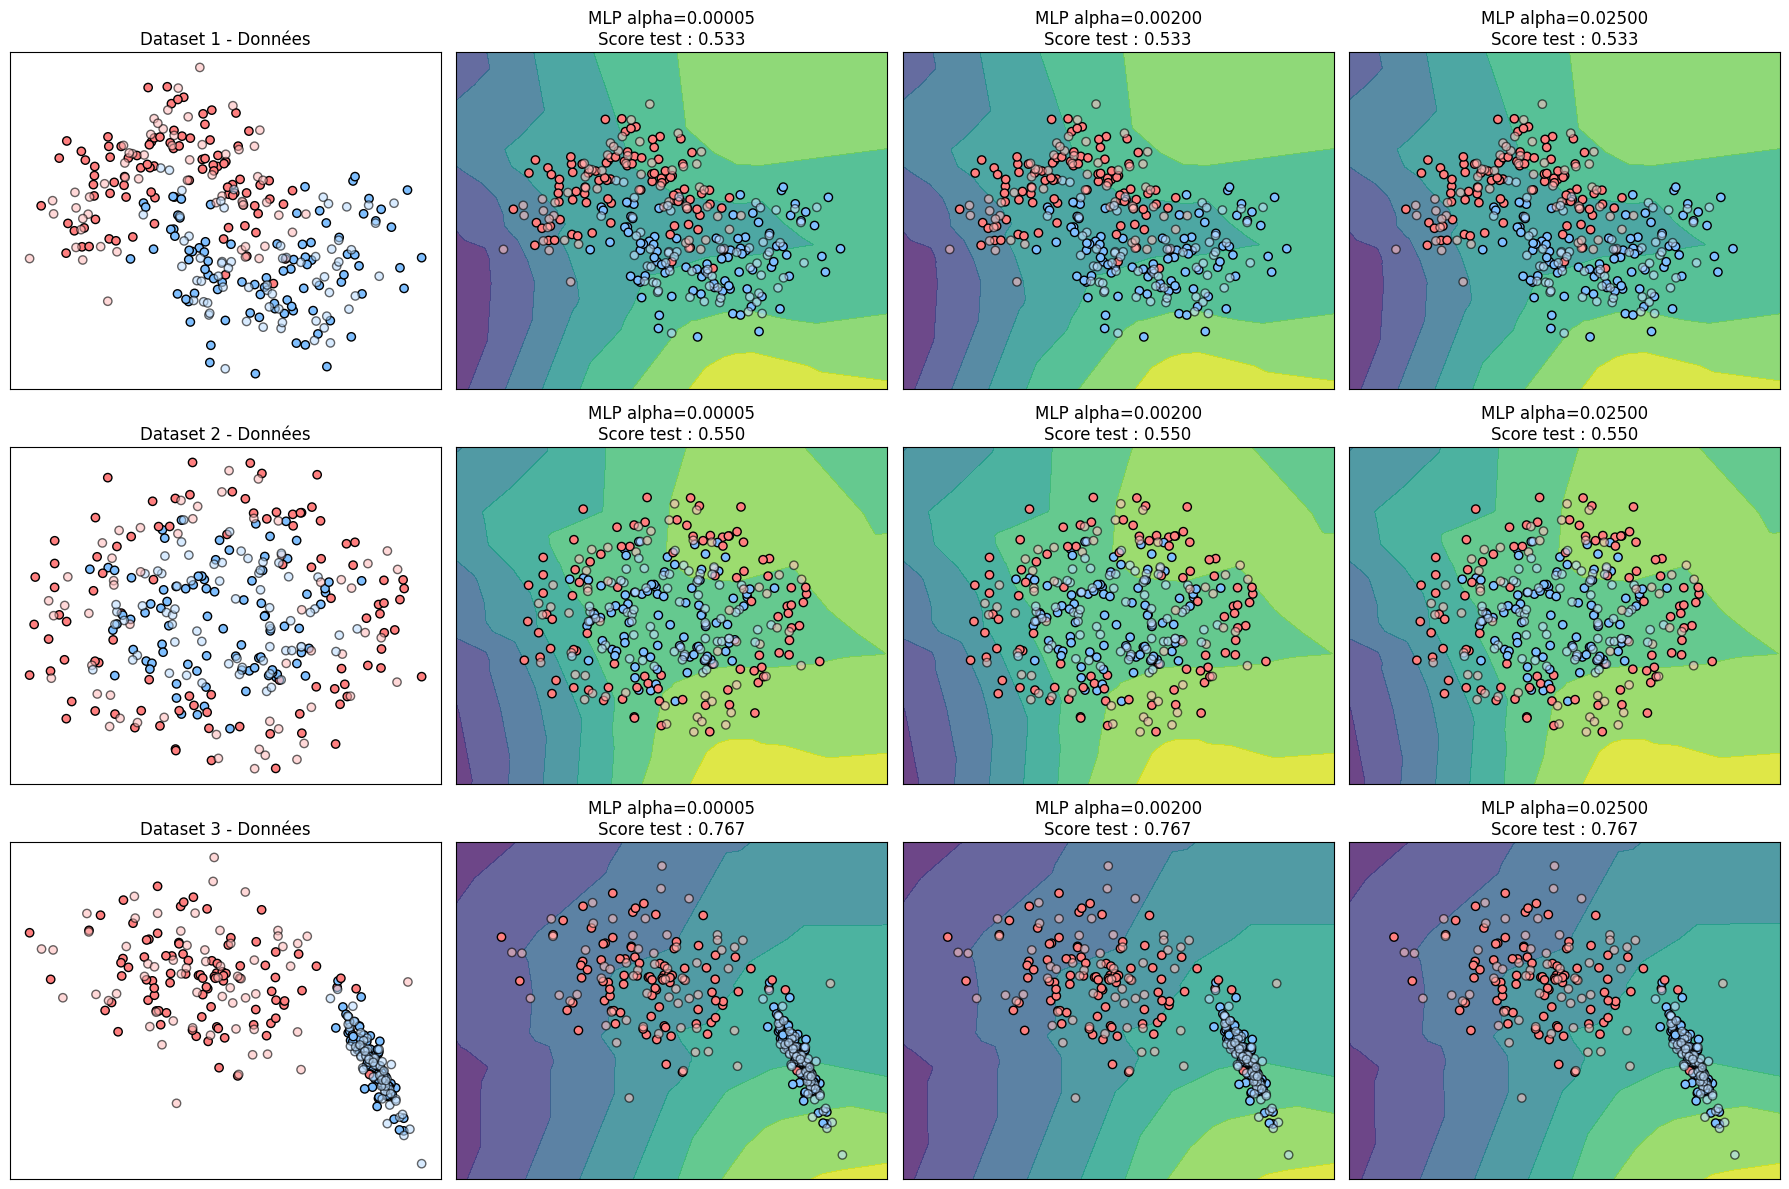

In [ ]:
# Création des datasets synthétiques variés
datasets = [
    make_moons(n_samples=300, noise=0.25, random_state=42),
    make_circles(n_samples=300, noise=0.2, factor=0.5, random_state=24),
    make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2,
                        n_clusters_per_class=1, random_state=7)
]

alphas = [5e-5, 2e-3, 2.5e-2]
classifiers = []
names = []

for alpha in alphas:
    clf = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(15, 10), alpha=alpha, max_iter=2000, early_stopping=True,
                      solver='adam', random_state=0)
    )
    classifiers.append(clf)
    names.append(f"MLP alpha={alpha:.5f}")

h = 0.02  # pas pour grille décision

plt.figure(figsize=(18, 12))
plot_index = 1

for dataset_id, (X, y) in enumerate(datasets, start=1):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)

    x_min, x_max = X[:, 0].min() - .6, X[:, 0].max() + .6
    y_min, y_max = X[:, 1].min() - .6, X[:, 1].max() + .6
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # Affichage des données
    plt.subplot(len(datasets), len(classifiers) + 1, plot_index)
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=ListedColormap(['#FF7F7F', '#7FBFFF']), edgecolor='k', label='Train')
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=ListedColormap(['#FFBFBF', '#BFDFFF']), edgecolor='k', alpha=0.6, label='Test')
    plt.title(f"Dataset {dataset_id} - Données")
    plt.xticks(())
    plt.yticks(())
    plot_index += 1

    # Itération sur classifieurs
    for name, clf in zip(names, classifiers):
        plt.subplot(len(datasets), len(classifiers) + 1, plot_index)
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)

        # Calcul de la frontière de décision
        if hasattr(clf, "decision_function"):
            Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
        else:
            Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]

        Z = Z.reshape(xx.shape)
        plt.contourf(xx, yy, Z, cmap=plt.cm.viridis, alpha=0.8)

        # Points train et test
        plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=ListedColormap(['#FF7F7F', '#7FBFFF']), edgecolor='k')
        plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=ListedColormap(['#FFBFBF', '#BFDFFF']), edgecolor='k', alpha=0.6)

        plt.title(f"{name}\nScore test : {score:.3f}")
        plt.xticks(())
        plt.yticks(())
        plot_index += 1

plt.tight_layout()
plt.show()


Classe Generator pour distributions synthétiques

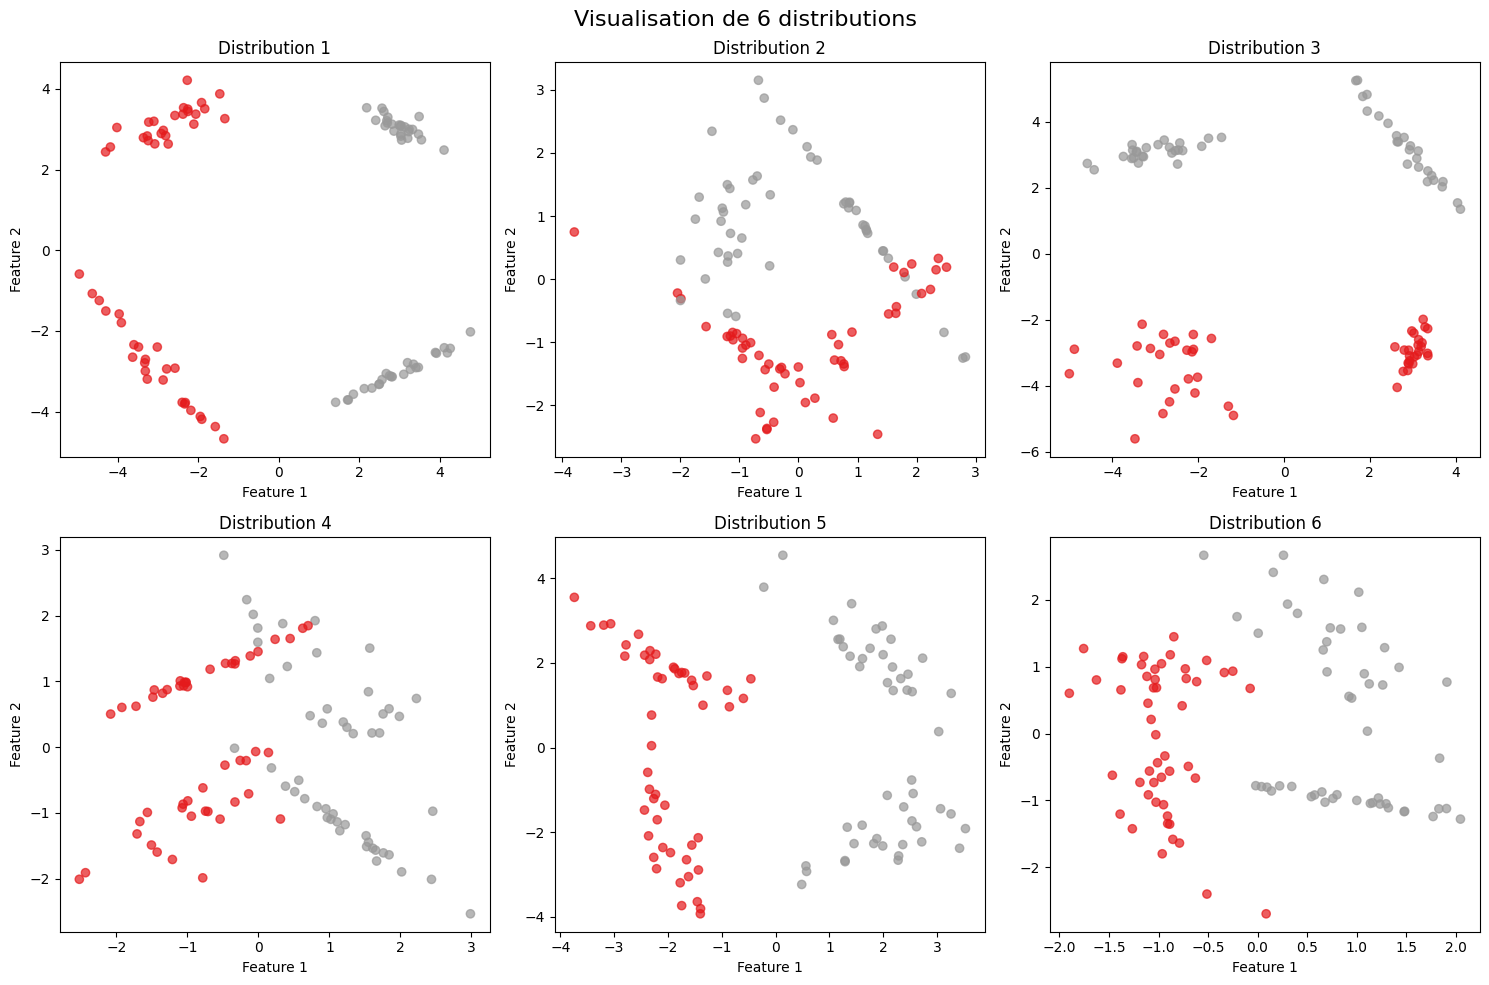

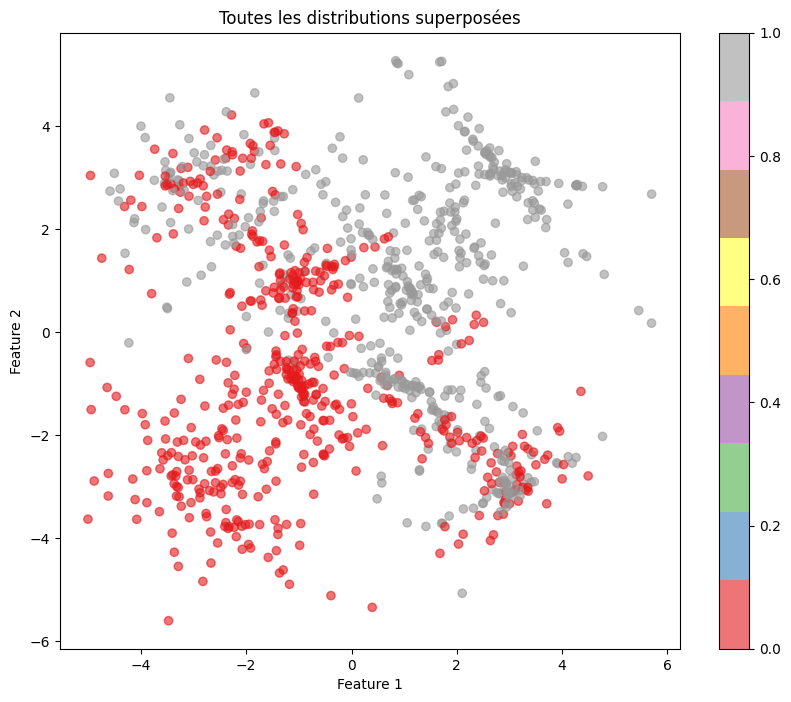

In [ ]:
class Generator:
    def __init__(self, n_dist=1000, n_points=100, class_sep=2.0, n_features=2, n_classes=2):
        self.n_dist = n_dist
        self.n_points = n_points
        self.class_sep = class_sep
        self.n_features = n_features
        self.n_classes = n_classes
        self.dist, self.labels, self.mean, self.std, self.min, self.max = self.generateDist()

    def generateDataLoader(self, all_dist=None, all_labels=None, batch_size=128, device='cpu', norm=True):
        if all_dist is None and all_labels is None:
            all_dist, all_labels = self.generateLinearDist(norm=norm)
        dataset = torch.utils.data.TensorDataset(all_dist, all_labels)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
        return dataloader

    def generateDist(self, device='cpu'):
        all_dist, all_labels = [], []
        for i in range(self.n_dist):
            dist, labels = make_classification(
                n_samples=self.n_points,
                n_features=self.n_features,
                n_informative=self.n_features,
                n_redundant=0,
                n_repeated=0,
                n_classes=self.n_classes,
                class_sep=rd.randint(1, 3)  # clarté de séparation des classes
            )
            dist = torch.tensor(dist, dtype=torch.float32, device=device)
            labels = torch.tensor(labels, dtype=torch.long, device=device)
            all_dist.append(dist)
            all_labels.append(labels)

        # Empiler en un seul tenseur
        all_dist = torch.stack(all_dist)  # n_dist, n_points, 2
        all_labels = torch.stack(all_labels)  # n_dist, n_points

        # Calcul des statistiques
        moyenne = all_dist.mean(dim=(0,1))
        ecart_type = all_dist.std(dim=(0,1))
        min_val = all_dist.amin(dim=(0,1))
        max_val = all_dist.amax(dim=(0,1))

        return all_dist, all_labels, moyenne, ecart_type, min_val, max_val

    def generateLinearDist(self, device='cpu', norm=True):
        all_dist = self.dist
        all_labels = self.labels

        all_dist = all_dist.view(-1, self.n_features)
        all_labels = all_labels.view(-1)

        if norm:
            all_dist = ((all_dist - self.mean) / (self.std))  # normalisation

        return all_dist, all_labels

    def plot(self, num_distributions=6):
        """
        Visualise les distributions générées
        """
        if self.n_features != 2:
            print("La visualisation n'est possible que pour 2 features")
            return

        # Créer une figure avec des sous-graphiques
        n_cols = 3
        n_rows = (num_distributions + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
        fig.suptitle(f"Visualisation de {min(num_distributions, self.n_dist)} distributions", fontsize=16)

        # Aplatir les axes pour un accès facile
        if num_distributions > 1:
            axes = axes.flatten()
        else:
            axes = [axes]

        # Tracer chaque distribution
        for i in range(min(num_distributions, self.n_dist)):
            dist = self.dist[i].cpu().numpy()
            labels = self.labels[i].cpu().numpy()

            axes[i].scatter(dist[:, 0], dist[:, 1], c=labels, cmap=plt.cm.Set1, alpha=0.7)
            axes[i].set_title(f"Distribution {i+1}")
            axes[i].set_xlabel("Feature 1")
            axes[i].set_ylabel("Feature 2")

        # Cacher les axes non utilisés
        for i in range(min(num_distributions, self.n_dist), len(axes)):
            axes[i].set_visible(False)

        plt.tight_layout()
        plt.show()

        # Afficher également toutes les distributions superposées
        all_dist, all_labels = self.generateLinearDist(norm=False)
        all_dist = all_dist.cpu().numpy()
        all_labels = all_labels.cpu().numpy()

        plt.figure(figsize=(10, 8))
        plt.scatter(all_dist[:, 0], all_dist[:, 1], c=all_labels, cmap=plt.cm.Set1, alpha=0.6)
        plt.title("Toutes les distributions superposées")
        plt.xlabel("Feature 1")
        plt.ylabel("Feature 2")
        plt.colorbar()
        plt.show()
# Créer le générateur
generator = Generator(n_dist=10, n_points=100)

# Visualiser les distributions
generator.plot(num_distributions=6)

=== DÉMARRAGE DE L'ENTRAÎNEMENT ===
Génération des graphiques pour les époques: 0, 10, 50
Device utilisé: cpu
✓ Graphique sauvegardé: Formation/frontiere_epoch_0.png
Epoque 0: Loss=0.6704, Acc=71.7%
Epoque 1: Loss=0.6281, Acc=75.0%
Epoque 2: Loss=0.6175, Acc=75.4%
Epoque 3: Loss=0.6130, Acc=75.3%
Epoque 4: Loss=0.6110, Acc=75.7%
Epoque 5: Loss=0.6094, Acc=75.3%
Epoque 6: Loss=0.6086, Acc=75.3%
Epoque 7: Loss=0.6077, Acc=75.1%
Epoque 8: Loss=0.6068, Acc=75.6%
Epoque 9: Loss=0.6055, Acc=75.1%
✓ Graphique sauvegardé: Formation/frontiere_epoch_10.png
Epoque 10: Loss=0.6054, Acc=75.5%
Epoque 11: Loss=0.6041, Acc=75.4%
Epoque 12: Loss=0.6052, Acc=75.2%
Epoque 13: Loss=0.6040, Acc=75.2%
Epoque 14: Loss=0.6033, Acc=75.5%
Epoque 15: Loss=0.6034, Acc=75.3%
Epoque 16: Loss=0.6051, Acc=74.8%
Epoque 17: Loss=0.6045, Acc=74.8%
Epoque 18: Loss=0.6044, Acc=74.7%
Epoque 19: Loss=0.6040, Acc=74.8%
Epoque 20: Loss=0.6036, Acc=74.8%
Epoque 21: Loss=0.6032, Acc=75.2%
Epoque 22: Loss=0.6025, Acc=75.6%
Epoqu

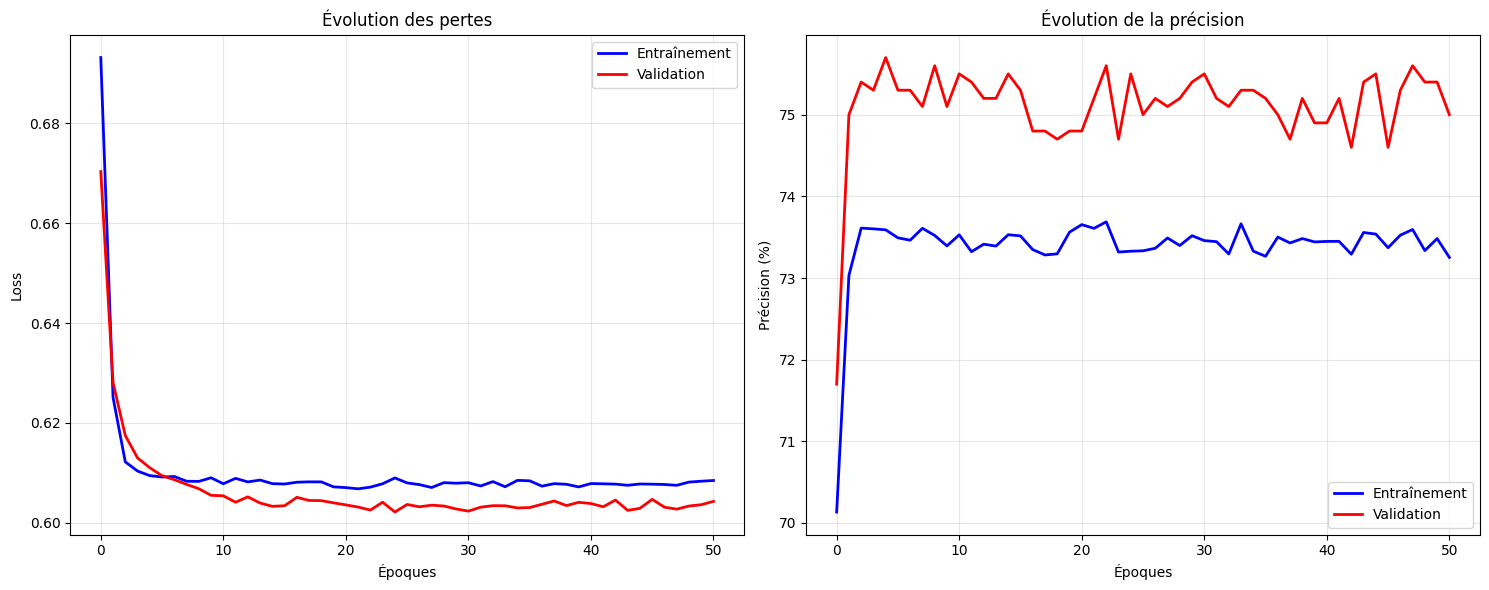

✓ Tous les graphiques ont été générés dans le dossier 'Formation/'
=== TERMINÉ ===
Graphiques générés:
1. Formation/frontiere_epoch_0.png
2. Formation/frontiere_epoch_10.png
3. Formation/frontiere_epoch_50.png
4. Formation/evolution_perte.png
5. Formation/evolution_precision.png


In [ ]:
# Classe Generator (doit être définie)
class Generator:
    def __init__(self, n_dist=1000, n_points=100, class_sep=2.0, n_features=2, n_classes=2):
        self.n_dist = n_dist
        self.n_points = n_points
        self.class_sep = class_sep
        self.n_features = n_features
        self.n_classes = n_classes
        self.dist, self.labels, self.mean, self.std, self.min, self.max = self.generateDist()

    def generateDist(self, device='cpu'):
        all_dist, all_labels = [], []
        for i in range(self.n_dist):
            dist, labels = make_classification(
                n_samples=self.n_points,
                n_features=self.n_features,
                n_informative=self.n_features,
                n_redundant=0,
                n_repeated=0,
                n_classes=self.n_classes,
                class_sep=rd.randint(1, 3)
            )
            dist = torch.tensor(dist, dtype=torch.float32, device=device)
            labels = torch.tensor(labels, dtype=torch.long, device=device)
            all_dist.append(dist)
            all_labels.append(labels)

        all_dist = torch.stack(all_dist)
        all_labels = torch.stack(all_labels)

        moyenne = all_dist.mean(dim=(0,1))
        ecart_type = all_dist.std(dim=(0,1))
        min_val = all_dist.amin(dim=(0,1))
        max_val = all_dist.amax(dim=(0,1))

        return all_dist, all_labels, moyenne, ecart_type, min_val, max_val

    def generateDataLoader(self, batch_size=128, device='cpu', norm=True):
        all_dist = self.dist.view(-1, self.n_features)
        all_labels = self.labels.view(-1)

        if norm:
            all_dist = ((all_dist - self.mean) / (self.std))

        dataset = torch.utils.data.TensorDataset(all_dist, all_labels)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
        return dataloader

    def generateLinearDist(self, device='cpu', norm=True):
        all_dist = self.dist.view(-1, self.n_features)
        all_labels = self.labels.view(-1)

        if norm:
            all_dist = ((all_dist - self.mean) / (self.std))

        return all_dist, all_labels

# Classe MLP
class My1stMlp(nn.Module):
    def __init__(self, input_dim=2, hidden_num=4, output_dim=1):
        super(My1stMlp, self).__init__()
        self.hidden_num = hidden_num
        self.input_dim = input_dim
        self.output_dim = 1

        self.input_layer = nn.Linear(input_dim, hidden_num, bias=True)
        self.hidden_layer = nn.Linear(hidden_num, hidden_num, bias=True)
        self.output_layer = nn.Linear(hidden_num, output_dim, bias=True)

    def forward(self, x):
        out = self.input_layer(x)
        out = torch.relu(out)
        out = self.hidden_layer(out)
        out = torch.relu(out)
        out = self.output_layer(out)
        return torch.sigmoid(out)

# Fonction pour visualiser les frontières
def draw_decision_boundary(samples, model, labels, epoch, save_path, train_min, train_max, device='cpu'):
    model.eval()
    plt.figure(figsize=(8, 6))

    # Créer une grille
    x_min, x_max = train_min[0].item() - 0.5, train_max[0].item() + 0.5
    y_min, y_max = train_min[1].item() - 0.5, train_max[1].item() + 0.5

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))

    # Prédire sur la grille
    with torch.no_grad():
        grid_data = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)
        Z = model(grid_data)
        Z = Z.cpu().numpy().reshape(xx.shape)

    # Tracer la frontière de décision
    plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.RdBu, levels=50)

    # Tracer les points de données
    scatter = plt.scatter(samples[:, 0], samples[:, 1], c=labels,
                          alpha=0.7, cmap=plt.cm.RdBu, edgecolors='k', s=30)

    plt.colorbar(scatter)
    plt.title(f"Frontière de décision - Époque {epoch}")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

    # Sauvegarder le graphique
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✓ Graphique sauvegardé: {save_path}")

# Fonction d'entraînement modifiée
def train_model_mlp_baseline(model, num_epochs=50, lr=0.001, weight_decay=1e-4):
    # Création des dataloaders
    valid_generator = Generator(n_dist=10, n_points=100)
    valid_loader = valid_generator.generateDataLoader(batch_size=128, norm=True)

    # Données de référence pour la visualisation
    ref_generator = Generator(n_dist=1, n_points=200)
    dist_ref, sample_labels = ref_generator.generateLinearDist(norm=True)
    dist_ref = dist_ref.cpu()
    sample_labels = sample_labels.cpu()

    # Device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device utilisé: {device}")
    model = model.to(device)

    # Optimizer et loss
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # Métriques
    losses_train, losses_valid, acc_train, acc_valid = [], [], [], []

    for epoch in range(num_epochs + 1):  # +1 pour inclure l'époque 50
        # Entraînement
        model.train()
        train_generator = Generator()
        train_loader = train_generator.generateDataLoader(batch_size=512, device=device)
        mean = train_generator.mean
        std = train_generator.std
        train_min = train_generator.min
        train_max = train_generator.max

        sum_train_loss = 0
        train_count = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            labels = labels.float().view(-1, 1)

            optimizer.zero_grad()
            preds = model(inputs)
            loss = criterion(preds, labels)
            loss.backward()
            optimizer.step()

            sum_train_loss += loss.item() * labels.numel()
            train_count += labels.numel()

        # Validation
        model.eval()
        sum_valid_loss = 0
        valid_count = 0

        with torch.no_grad():
            for inputs, labels in valid_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                inputs = ((inputs - mean) / (std))
                labels = labels.float().view(-1, 1)
                preds = model(inputs)
                loss = criterion(preds, labels)

                sum_valid_loss += loss.item() * labels.numel()
                valid_count += labels.numel()

        # Calcul des métriques
        mean_train_loss = sum_train_loss / train_count
        mean_valid_loss = sum_valid_loss / valid_count
        losses_train.append(mean_train_loss)
        losses_valid.append(mean_valid_loss)

        # Calcul de la précision
        def get_accuracy(model, loader, device='cpu'):
            model.eval()
            correct = 0
            total = 0
            with torch.no_grad():
                for inputs, labels in loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)
                    predicted = (outputs > 0.5).float()
                    total += labels.size(0)
                    correct += (predicted.view(-1) == labels.float()).sum().item()
            return 100 * correct / total

        acc_train.append(get_accuracy(model, train_loader, device=device))
        acc_valid.append(get_accuracy(model, valid_loader, device=device))

        # Sauvegarder les graphiques aux époques spécifiques
        if epoch in [0, 10, 50]:
            draw_decision_boundary(
                dist_ref.numpy(),
                model,
                sample_labels.numpy(),
                epoch,
                f"Formation/frontiere_epoch_{epoch}.png",
                train_min,
                train_max,
                device
            )

        print(f"Epoque {epoch}: Loss={mean_valid_loss:.4f}, Acc={acc_valid[-1]:.1f}%")

    # Sauvegarder les courbes d'apprentissage
    plt.figure(figsize=(15, 6))

    # Courbe de perte
    plt.subplot(1, 2, 1)
    plt.plot(losses_train, 'b-', label='Entraînement', linewidth=2)
    plt.plot(losses_valid, 'r-', label='Validation', linewidth=2)
    plt.title('Évolution des pertes')
    plt.xlabel('Époques')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig("Formation/evolution_perte.png", dpi=300, bbox_inches='tight')

    # Courbe de précision
    plt.subplot(1, 2, 2)
    plt.plot(acc_train, 'b-', label='Entraînement', linewidth=2)
    plt.plot(acc_valid, 'r-', label='Validation', linewidth=2)
    plt.title('Évolution de la précision')
    plt.xlabel('Époques')
    plt.ylabel('Précision (%)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig("Formation/evolution_precision.png", dpi=300, bbox_inches='tight')

    plt.tight_layout()
    plt.show()

    print("✓ Tous les graphiques ont été générés dans le dossier 'Formation/'")
    return model

# Exécution principale
if __name__ == "__main__":
    print("=== DÉMARRAGE DE L'ENTRAÎNEMENT ===")
    print("Génération des graphiques pour les époques: 0, 10, 50")

    # Créer le modèle
    model = My1stMlp(input_dim=2, hidden_num=8, output_dim=1)

    # Entraîner le modèle
    trained_model = train_model_mlp_baseline(
        model,
        num_epochs=50,
        lr=0.001,
        weight_decay=1e-4
    )

    print("=== TERMINÉ ===")
    print("Graphiques générés:")
    print("1. Formation/frontiere_epoch_0.png")
    print("2. Formation/frontiere_epoch_10.png")
    print("3. Formation/frontiere_epoch_50.png")
    print("4. Formation/evolution_perte.png")
    print("5. Formation/evolution_precision.png")

=== AFFICHAGE DES GRAPHIQUES ===

📊 Formation/frontiere_epoch_0.png:


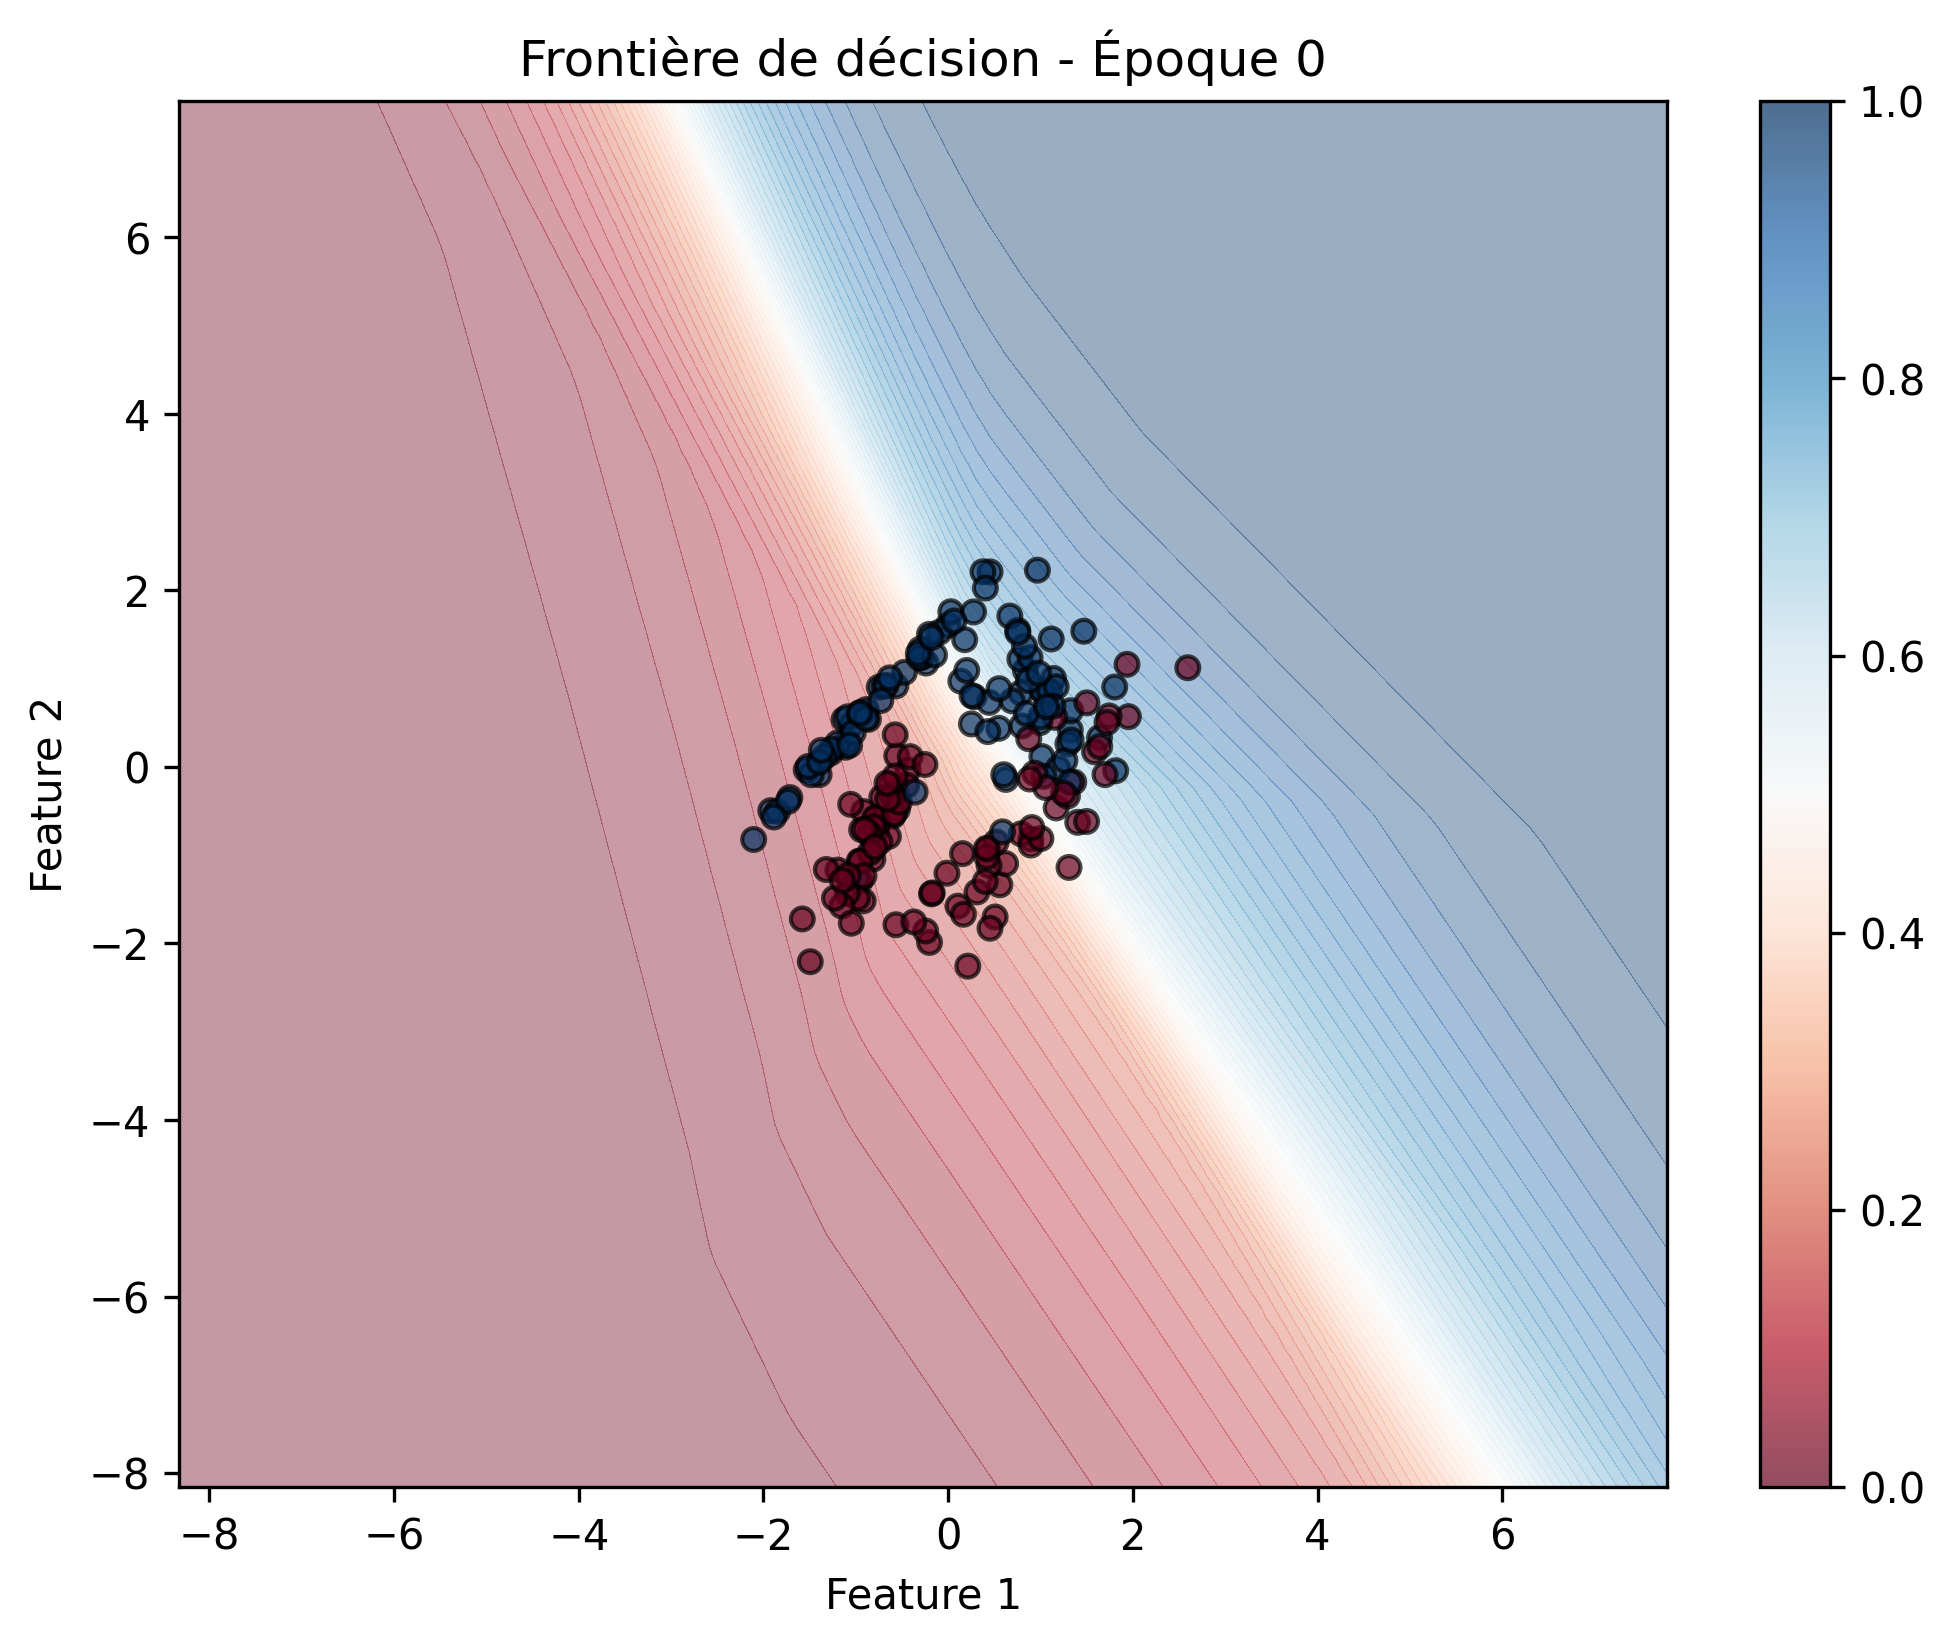


📊 Formation/frontiere_epoch_10.png:


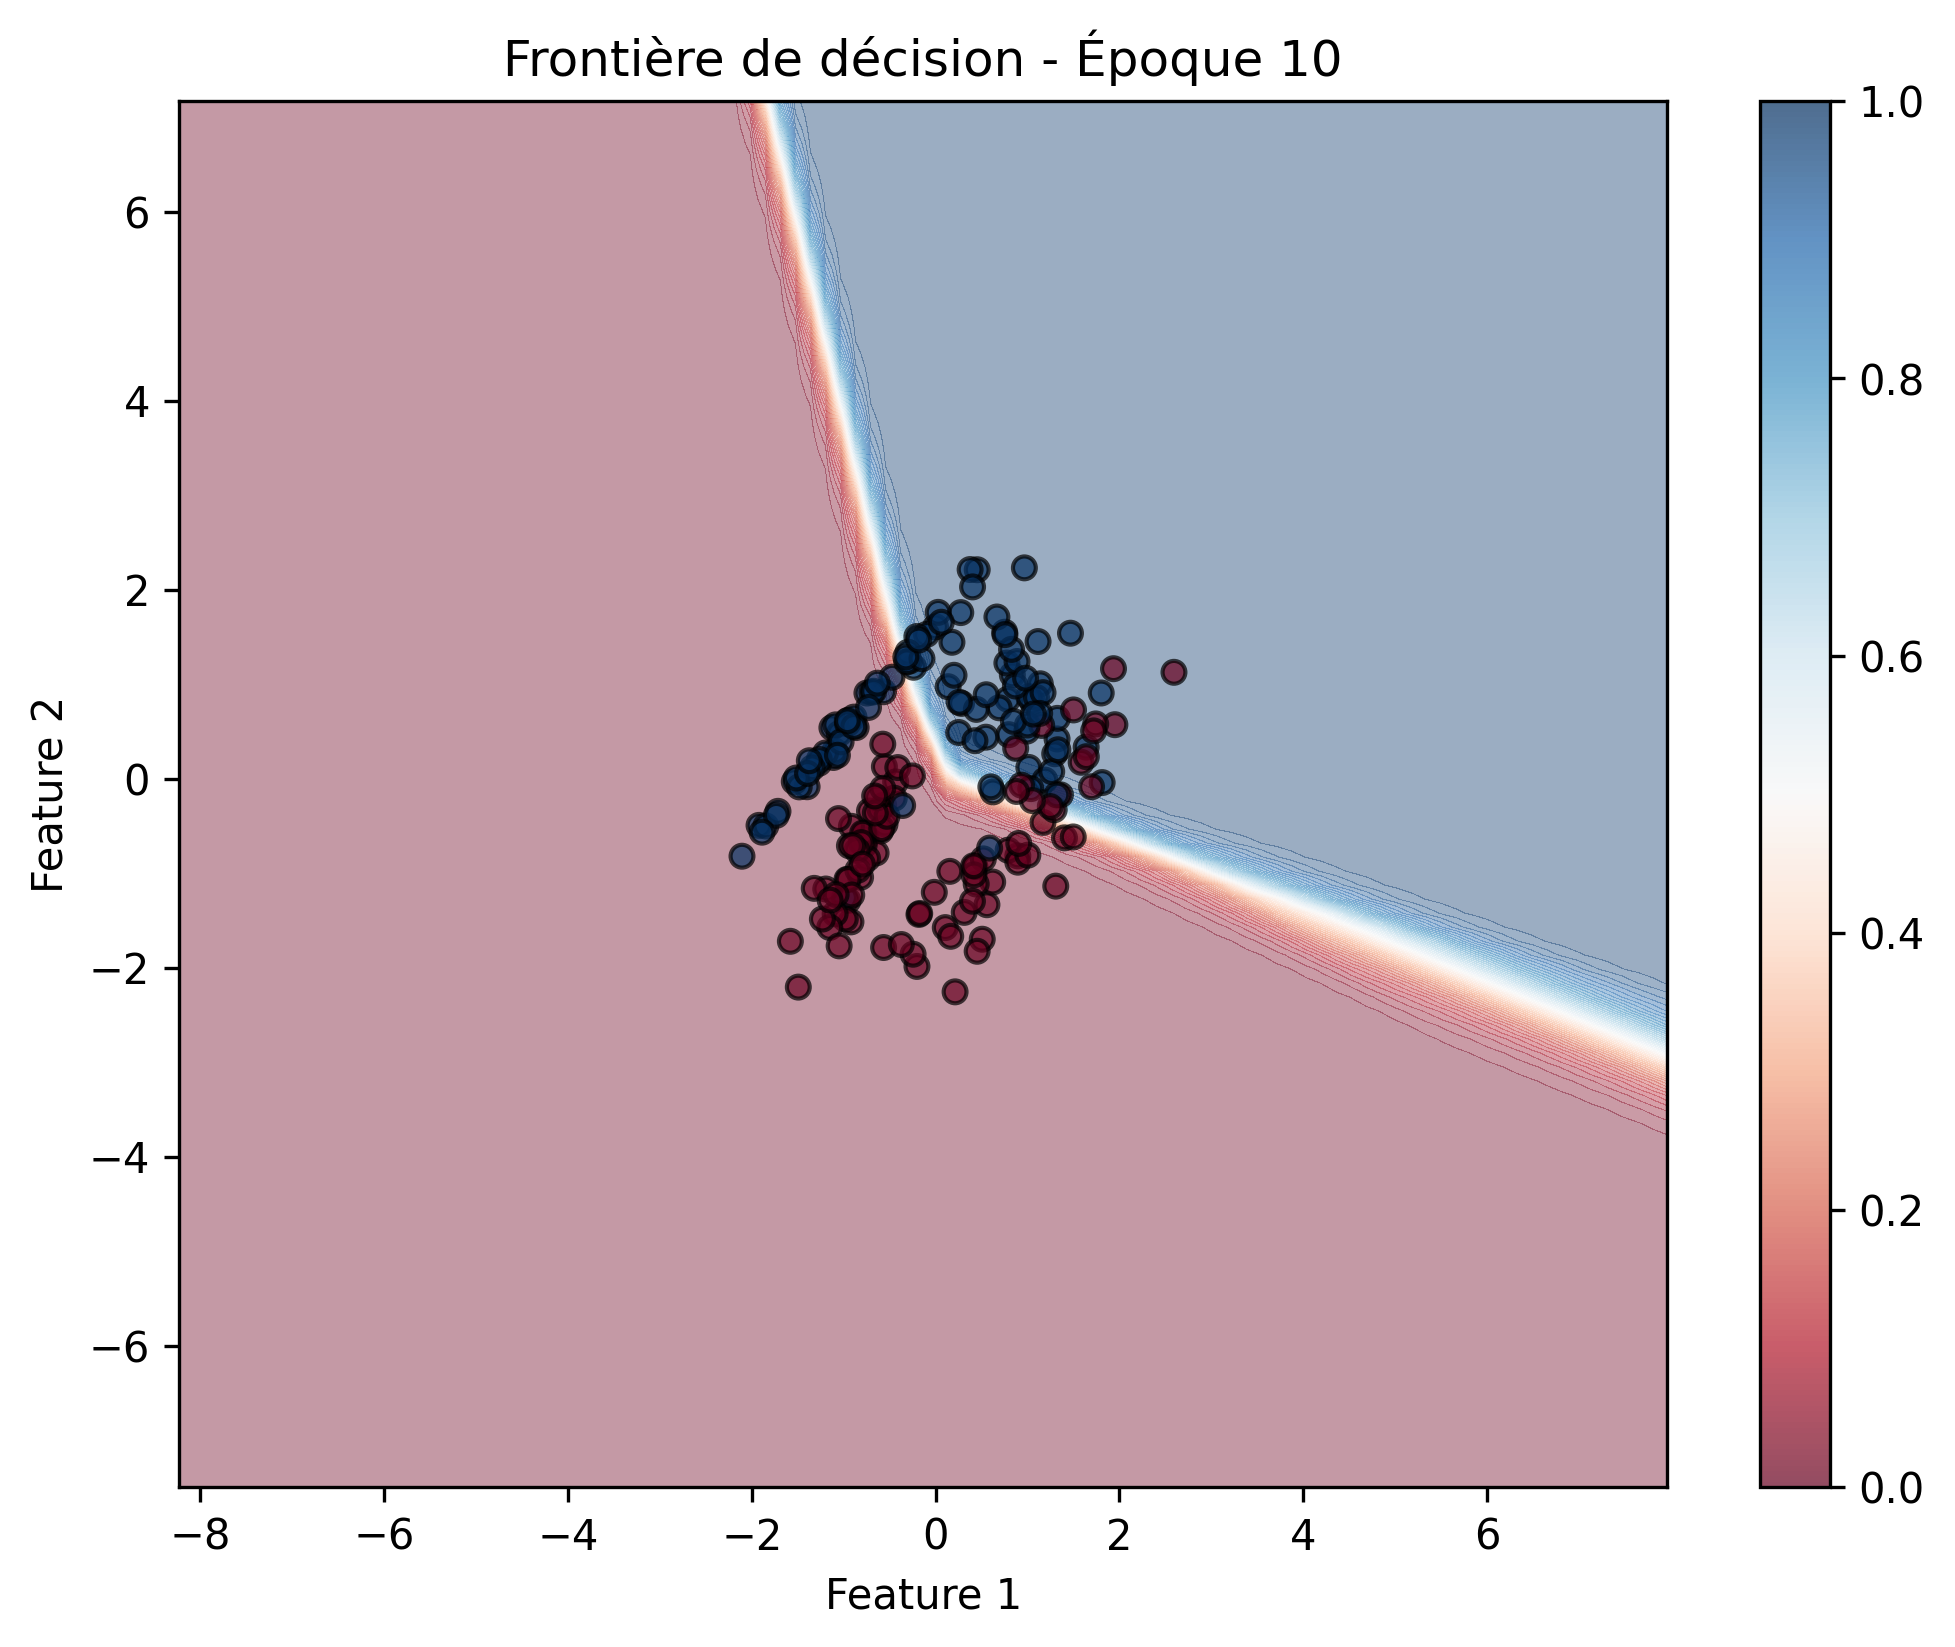


📊 Formation/frontiere_epoch_50.png:


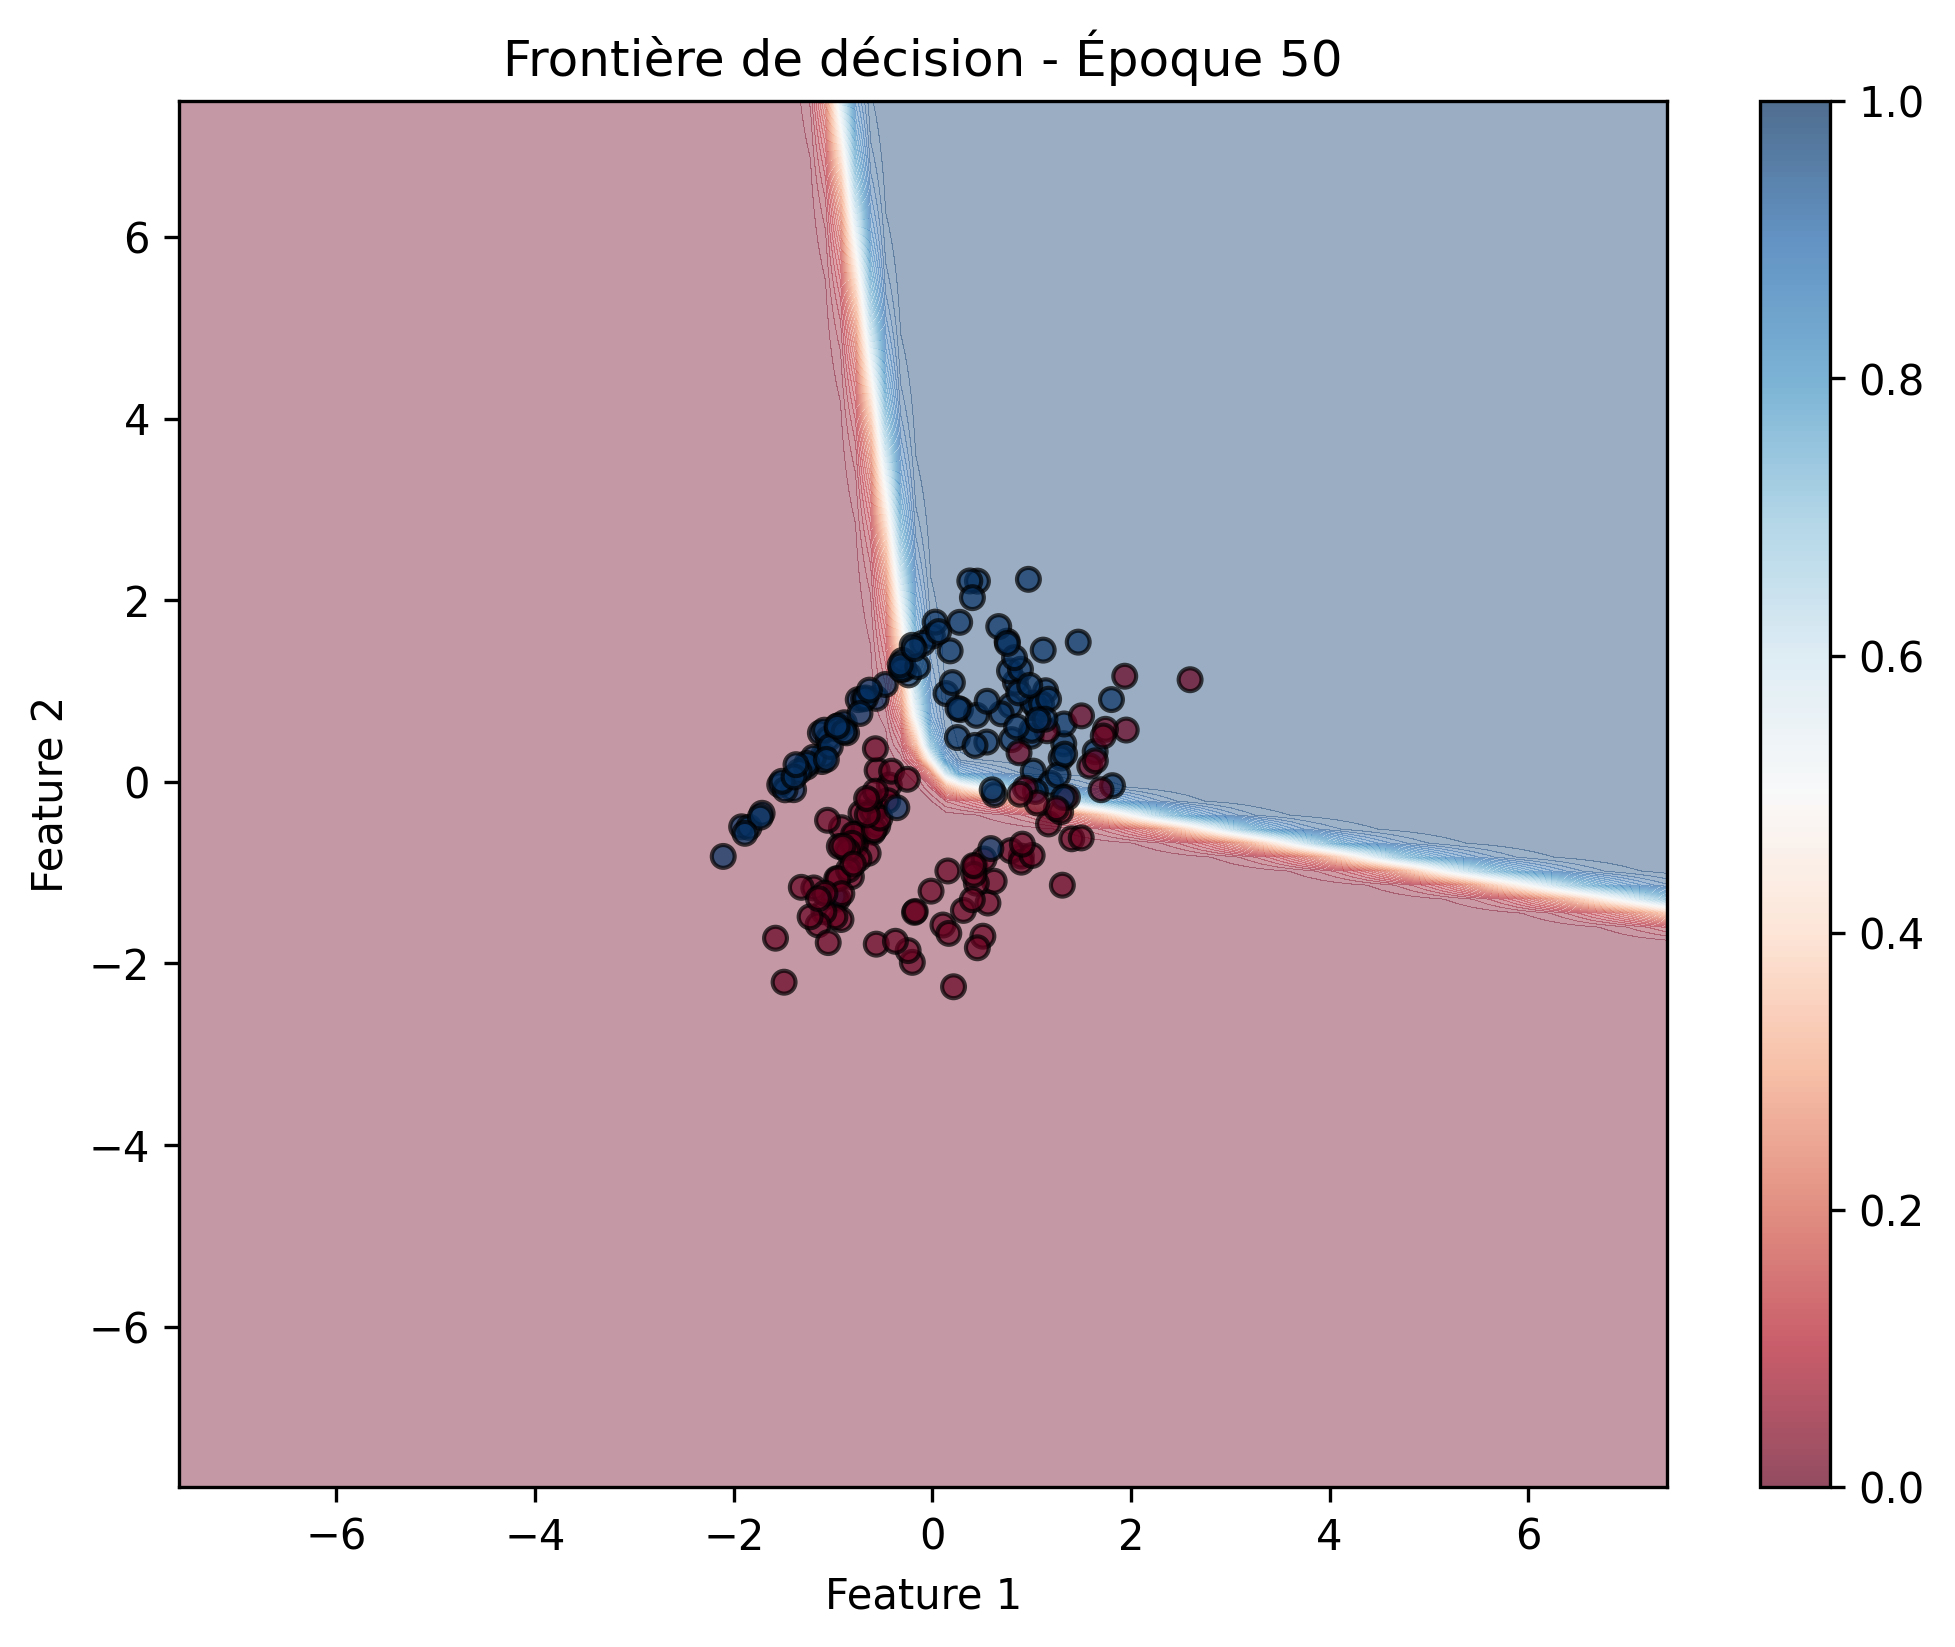


📊 Formation/evolution_perte.png:


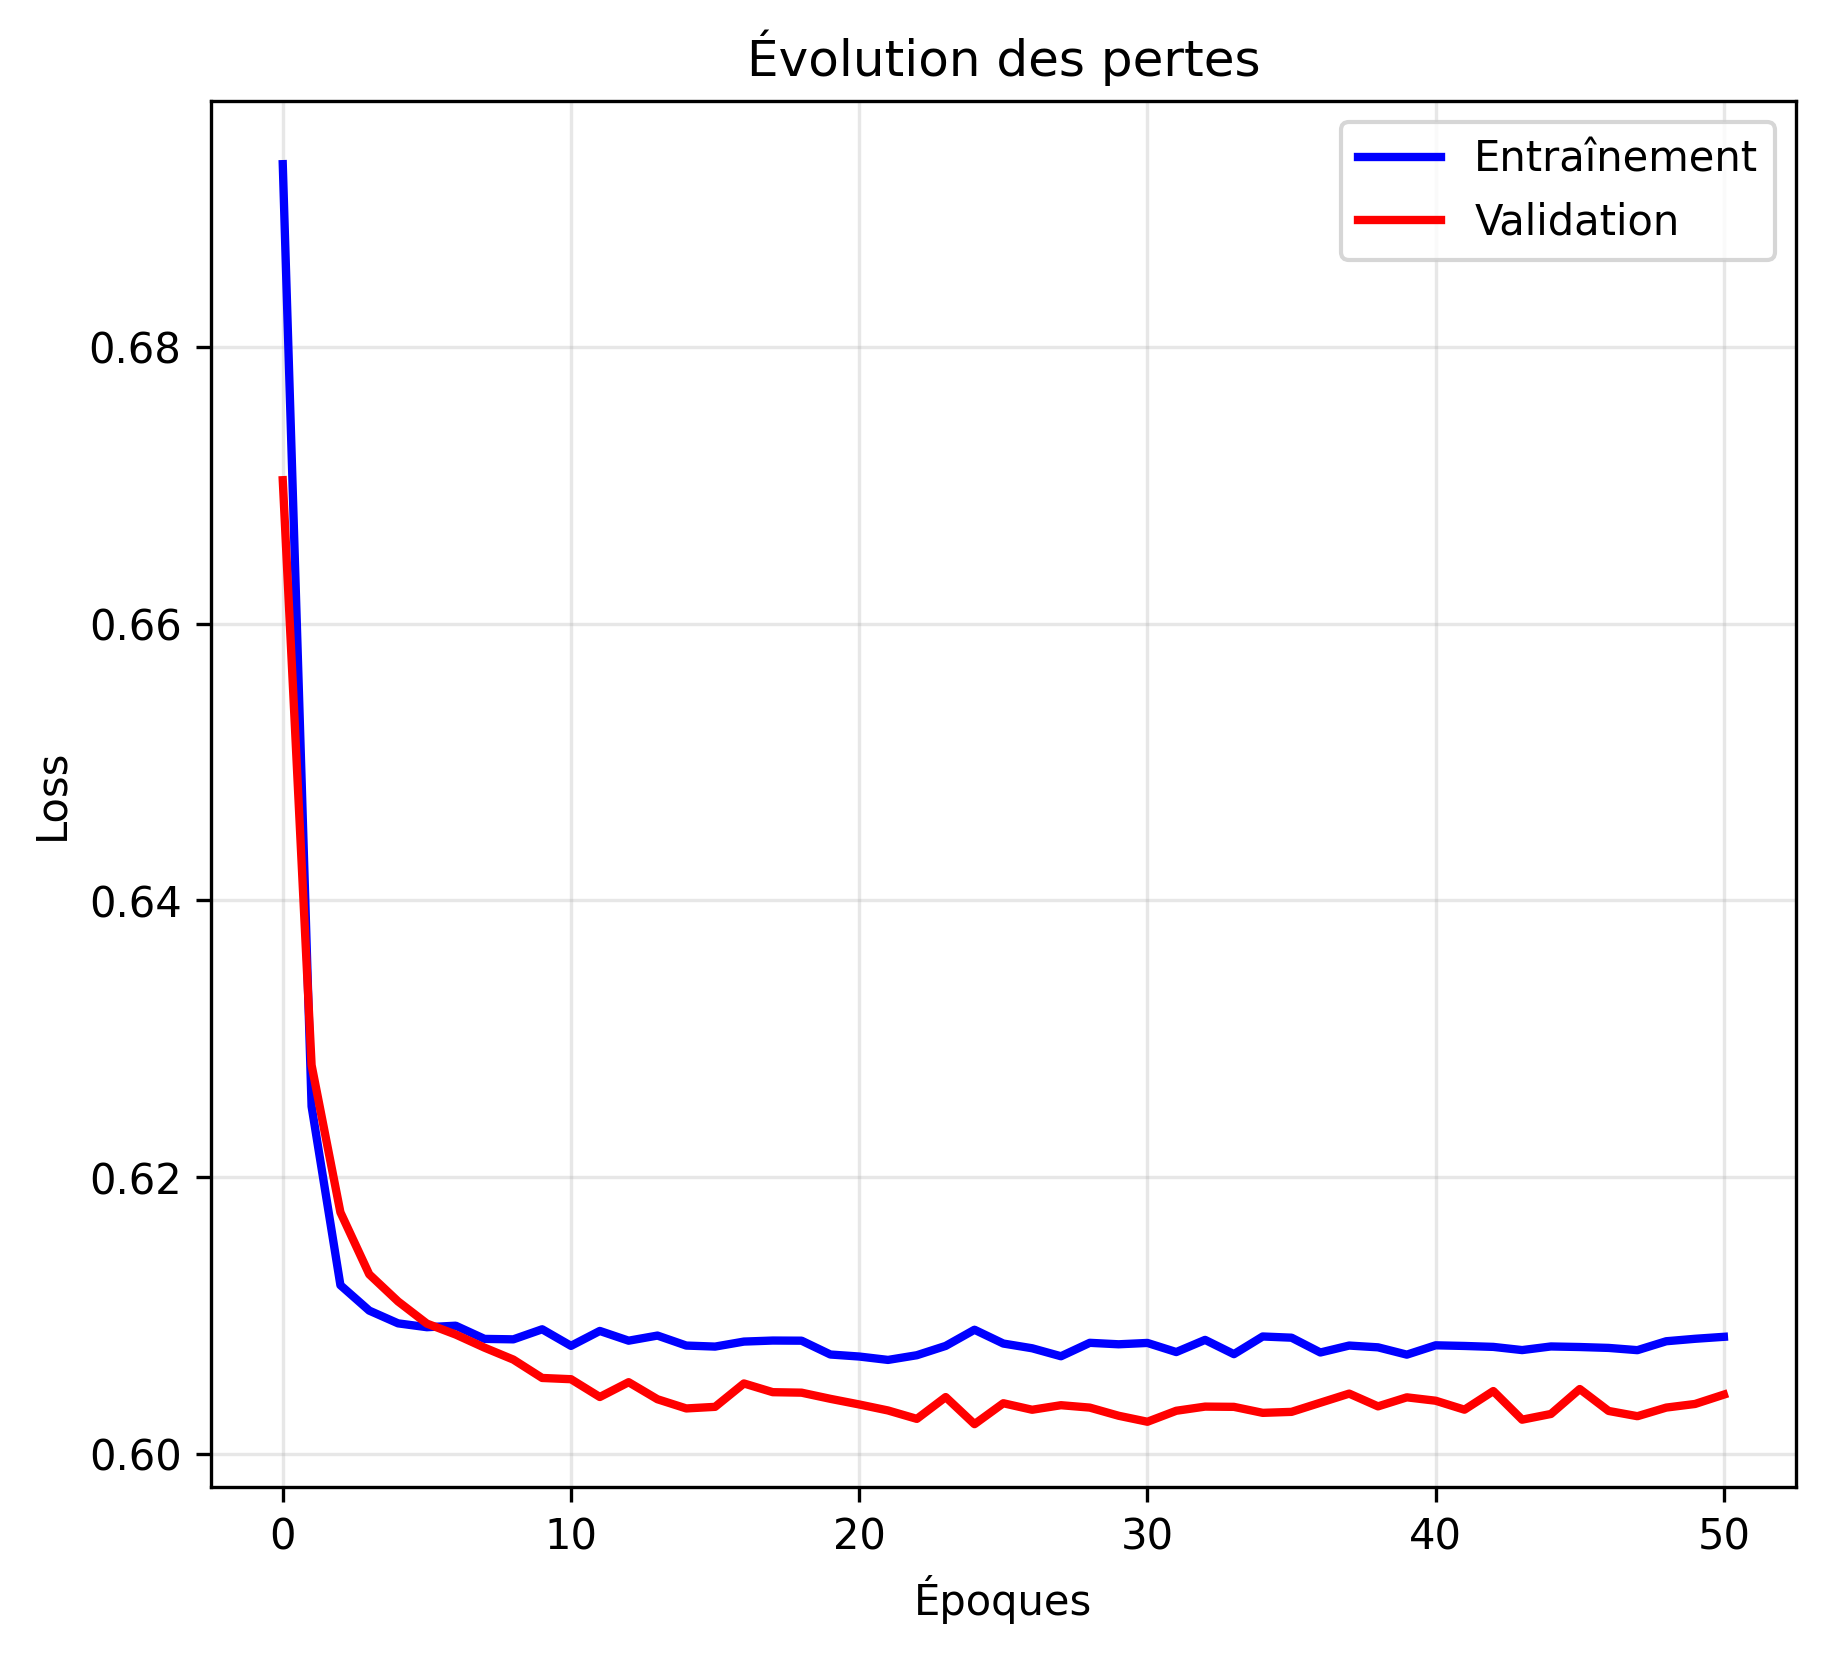


📊 Formation/evolution_precision.png:


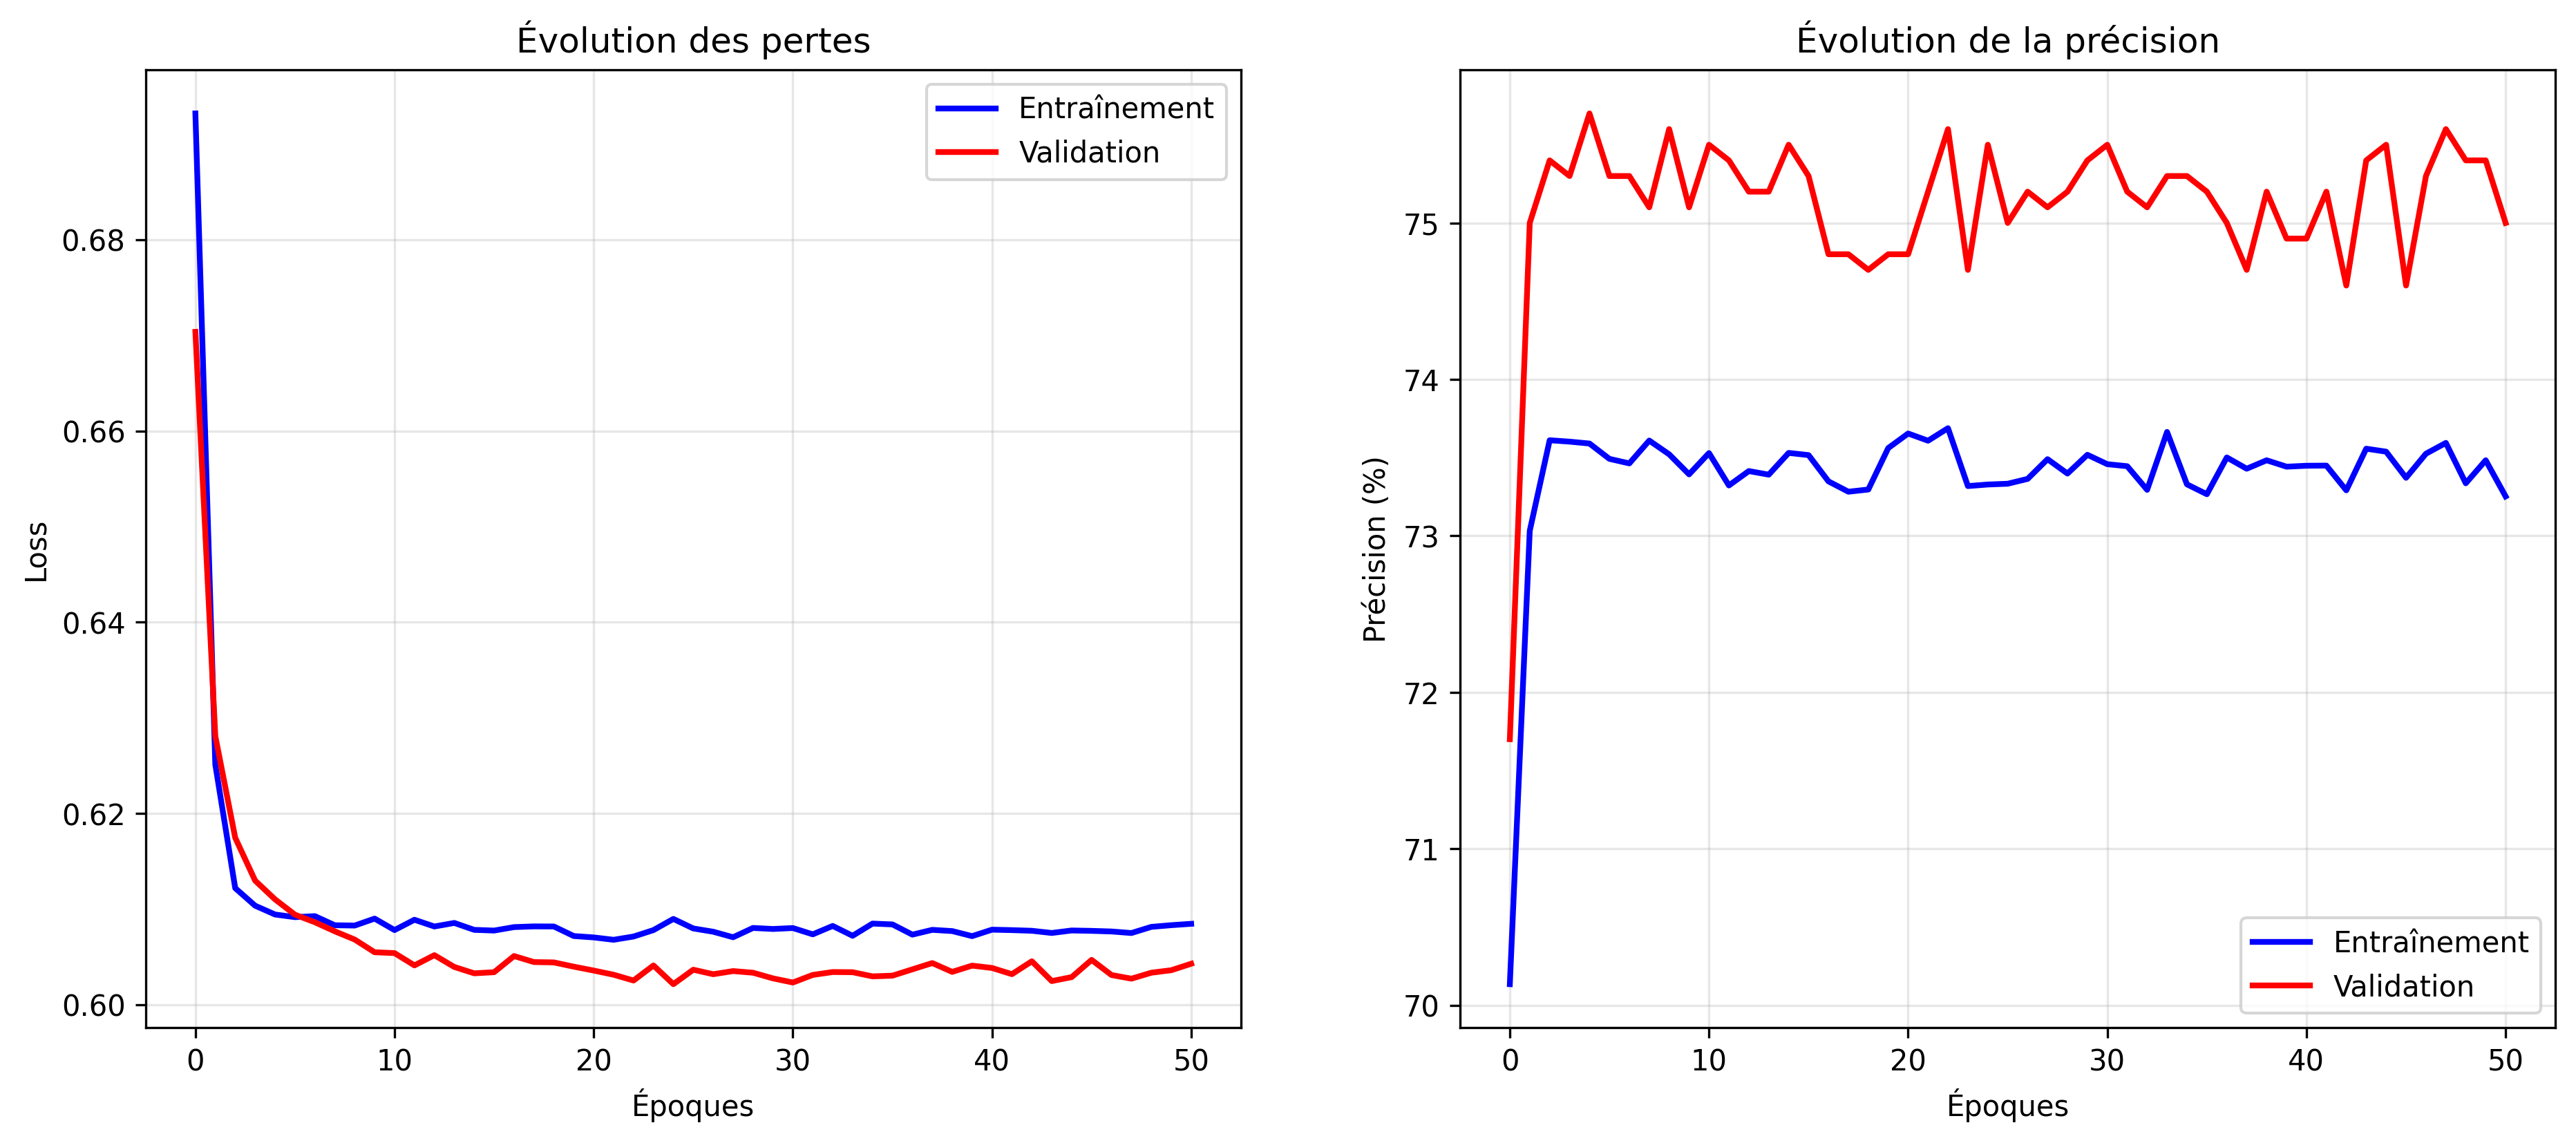

In [103]:
# Afficher les 5 graphiques
print("=== AFFICHAGE DES GRAPHIQUES ===")

graphiques = [
    "Formation/frontiere_epoch_0.png",
    "Formation/frontiere_epoch_10.png",
    "Formation/frontiere_epoch_50.png",
    "Formation/evolution_perte.png",
    "Formation/evolution_precision.png"
]

for graphique in graphiques:
    if os.path.exists(graphique):
        print(f"\n📊 {graphique}:")
        display(Image(filename=graphique, width=400))
    else:
        print(f"❌ Fichier non trouvé: {graphique}")


<br><br>


<h1 style="color:blue; font-size:32px;">
CHAPITRE 4: RECONSTRUCTION D'IMAGES
</h1>


Reconstruction d'images avec des réseaux de neurones
    
    Théorie:
    Problème: Approximer f: ℝ² → ℝ tel que f(x,y) = C
    où C est la valeur du pixel en (x,y)
    
    Approche:
    1. Coordonnées (x,y) → Entrée du réseau
    2. Réseau de neurones → Approximation de f
    3. Sortie → Valeur prédite du pixel

🎯 Entraînement du modèle...
   Échantillons: 4096
   Epochs: 100
   Batch size: 512
Epoch 1/100
8/8 - 2s - 227ms/step - loss: 0.2307 - mae: 0.4782 - val_loss: 0.1665 - val_mae: 0.4074
Epoch 2/100
8/8 - 0s - 29ms/step - loss: 0.2111 - mae: 0.4497 - val_loss: 0.1167 - val_mae: 0.3398
Epoch 3/100
8/8 - 0s - 22ms/step - loss: 0.1988 - mae: 0.4218 - val_loss: 0.0783 - val_mae: 0.2770
Epoch 4/100
8/8 - 0s - 14ms/step - loss: 0.1927 - mae: 0.3967 - val_loss: 0.0545 - val_mae: 0.2303
Epoch 5/100
8/8 - 0s - 18ms/step - loss: 0.1909 - mae: 0.3794 - val_loss: 0.0444 - val_mae: 0.2080
Epoch 6/100
8/8 - 0s - 13ms/step - loss: 0.1892 - mae: 0.3735 - val_loss: 0.0472 - val_mae: 0.2156
Epoch 7/100
8/8 - 0s - 19ms/step - loss: 0.1870 - mae: 0.3749 - val_loss: 0.0507 - val_mae: 0.2244
Epoch 8/100
8/8 - 0s - 14ms/step - loss: 0.1851 - mae: 0.3763 - val_loss: 0.0532 - val_mae: 0.2304
Epoch 9/100
8/8 - 0s - 14ms/step - loss: 0.1830 - mae: 0.3762 - val_loss: 0.0556 - val_mae: 0.2357
Epoch 10/100
8/8 - 0s - 

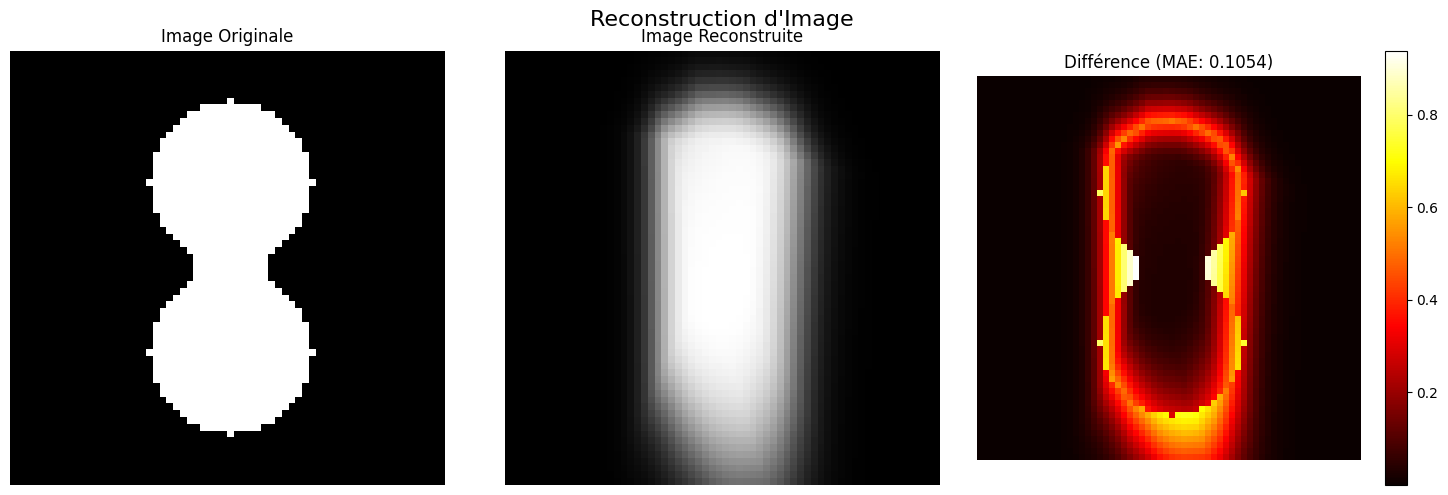

In [ ]:
class ReconstructionImage:
    """
    Reconstruction d'images avec des réseaux de neurones
    """

    def __init__(self):
        self.model = None
        self.img_shape = None
        self.img_original = None

    def creer_image_test(self, size=(64, 64), pattern='gradient'):
        h, w = size
        if pattern == 'gradient':
            x, y = np.meshgrid(np.linspace(0, 1, w), np.linspace(0, 1, h))
            img = (x + y) / 2
        elif pattern == 'circle':
            x, y = np.meshgrid(np.linspace(-1, 1, w), np.linspace(-1, 1, h))
            img = 1 - np.sqrt(x**2 + y**2)
            img = np.clip(img, 0, 1)
        elif pattern == 'checkerboard':
            img = np.zeros((h, w))
            for i in range(0, h, 8):
                for j in range(0, w, 8):
                    if ((i // 8) + (j // 8)) % 2 == 0:
                        img[i:i+8, j:j+8] = 1
        elif pattern == 'random':
            img = np.random.rand(h, w)
        else:
            raise ValueError(f"Pattern '{pattern}' non reconnu")
        self.img_original = img.astype(np.float32)
        self.img_shape = size
        return img

    def creer_image_os_stylise(self, size=(64,64)):
        h, w = size
        img = np.zeros((h, w), dtype=np.float32)

        rr, cc = np.ogrid[:h, :w]
        center1 = (int(h*0.3), int(w*0.5))
        center2 = (int(h*0.7), int(w*0.5))
        radius = int(h*0.2)

        circle1 = (rr - center1[0])**2 + (cc - center1[1])**2 <= radius**2
        circle2 = (rr - center2[0])**2 + (cc - center2[1])**2 <= radius**2
        rect = (rr > center1[0]) & (rr < center2[0]) & (np.abs(cc - center1[1]) < radius//2)

        img[circle1 | circle2 | rect] = 1.0

        self.img_original = img
        self.img_shape = size
        return img

    def preparer_donnees(self, img):
        h, w = img.shape
        x, y = np.meshgrid(np.arange(w), np.arange(h))
        X = np.stack([x.ravel(), y.ravel()], axis=1) / np.array([w-1, h-1])
        Y = img.ravel()[:, None]
        return X, Y

    def creer_modele(self, architecture='simple'):
        if architecture == 'simple':
            self.model = Sequential([
                Dense(64, activation='relu', input_shape=(2,)),
                Dense(64, activation='relu'),
                Dense(1, activation='sigmoid')
            ])
        elif architecture == 'deep':
            self.model = Sequential([
                Dense(128, activation='relu', input_shape=(2,)),
                Dense(128, activation='relu'),
                Dense(64, activation='relu'),
                Dense(32, activation='relu'),
                Dense(1, activation='sigmoid')
            ])
        elif architecture == 'wide':
            self.model = Sequential([
                Dense(256, activation='relu', input_shape=(2,)),
                Dense(256, activation='relu'),
                Dense(1, activation='sigmoid')
            ])
        else:
            raise ValueError(f"Architecture '{architecture}' non reconnue")
        self.model.compile(optimizer='adam', loss='mse', metrics=['mae'])
        return self.model

    def entrainer(self, X, Y, epochs=100, batch_size=512, verbose=1):
        if self.model is None:
            raise ValueError("Modèle non créé. Utilisez creer_modele() d'abord.")
        print(f"🎯 Entraînement du modèle...")
        print(f"   Échantillons: {len(X)}")
        print(f"   Epochs: {epochs}")
        print(f"   Batch size: {batch_size}")
        history = self.model.fit(X, Y, epochs=epochs, batch_size=batch_size,
                                 verbose=verbose, validation_split=0.1)
        return history

    def reconstruire(self, resolution=None):
        if self.model is None:
            raise ValueError("Modèle non entraîné")
        if resolution is None:
            resolution = self.img_shape
        h, w = resolution
        x, y = np.meshgrid(np.arange(w), np.arange(h))
        X_grid = np.stack([x.ravel(), y.ravel()], axis=1) / np.array([w-1, h-1])
        Y_pred = self.model.predict(X_grid, verbose=0)
        img_reconstruit = Y_pred.reshape(h, w)
        return img_reconstruit

    def visualiser_resultats(self, img_reconstruit, titre="Reconstruction d'Image"):
        plt.figure(figsize=(15, 5))
        plt.subplot(1, 3, 1)
        plt.imshow(self.img_original, cmap='gray')
        plt.title('Image Originale')
        plt.axis('off')
        plt.subplot(1, 3, 2)
        plt.imshow(img_reconstruit, cmap='gray')
        plt.title('Image Reconstruite')
        plt.axis('off')
        plt.subplot(1, 3, 3)
        diff = np.abs(self.img_original - img_reconstruit)
        plt.imshow(diff, cmap='hot')
        plt.title(f'Différence (MAE: {np.mean(diff):.4f})')
        plt.axis('off')
        plt.colorbar()
        plt.suptitle(titre, fontsize=16)
        plt.tight_layout()
        plt.show()

# --- Exemple d'utilisation complet ---

ri = ReconstructionImage()

# Générer une image stylisée en forme d'os
img_test = ri.creer_image_os_stylise(size=(64,64))

# Préparer les données
X, Y = ri.preparer_donnees(img_test)

# Créer et compiler le modèle
ri.creer_modele(architecture='simple')

# Entraîner le modèle
ri.entrainer(X, Y, epochs=100, batch_size=512, verbose=2)

# Reconstruire l'image
img_reconstruit = ri.reconstruire()

# Visualiser les résultats
ri.visualiser_resultats(img_reconstruit)




<br><br>


<h1 style="color:blue; font-size:32px;">
CHAPITRE 5: RÉSEAUX CONVOLUTIFS (CNN)
</h1>


Analyse et visualisation des réseaux de neurones convolutifs
    
    Théorie:
    Les CNN utilisent:
    1. Convolution: Détection de motifs locaux
    2. Pooling: Réduction de dimensionnalité
    3. Filtres: Apprentissage automatique de caractéristiques

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step


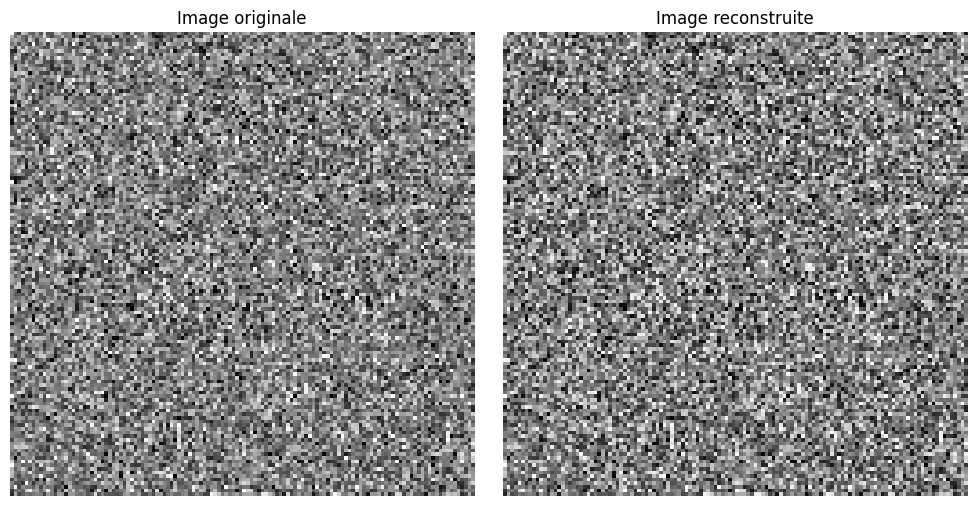

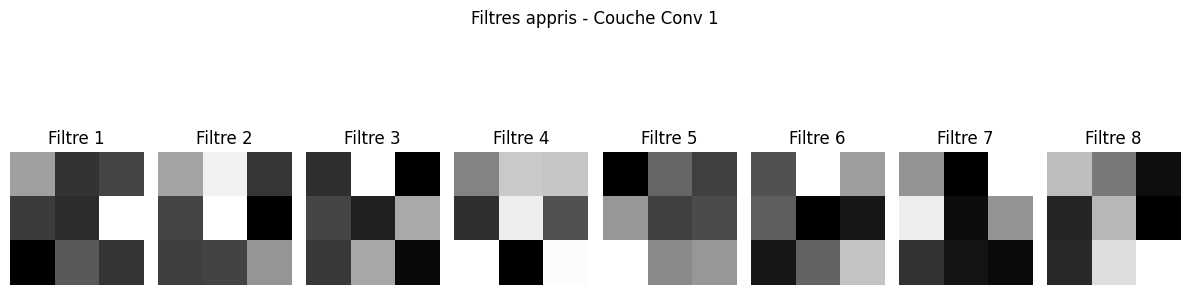

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


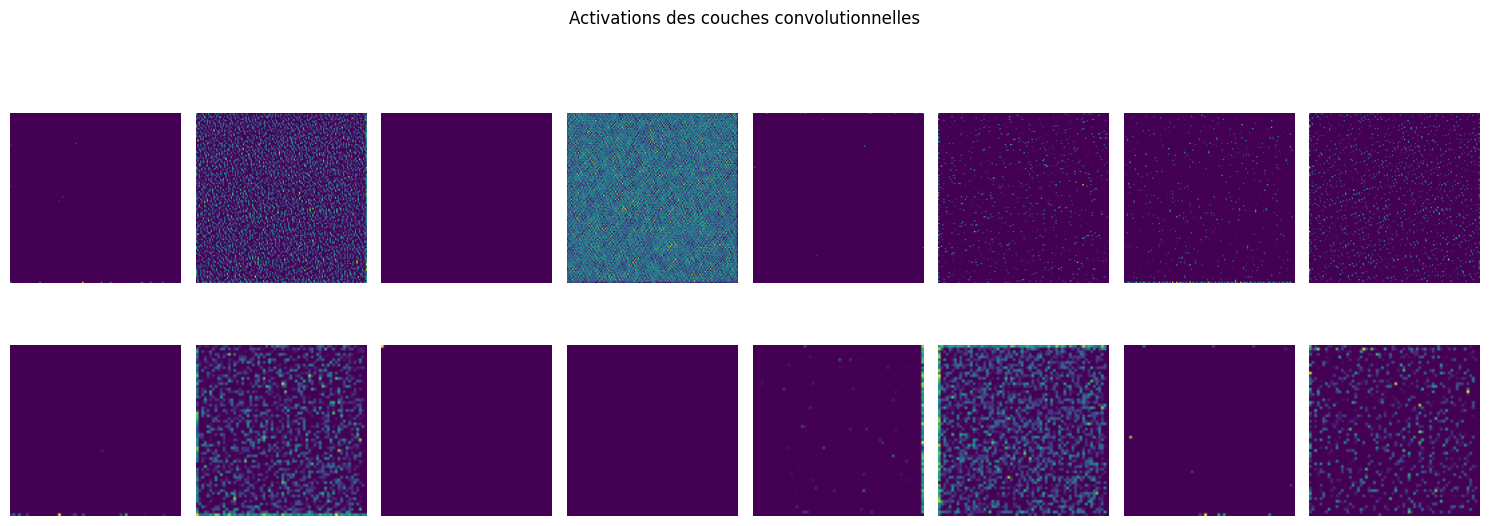

In [ ]:

# 1. Image aléatoire
img_np = np.clip(np.random.normal(loc=0.5, scale=0.2, size=(128, 128)), 0, 1).astype(np.float32)

# 2. Définition du modèle CNN avec API fonctionnelle
input_layer = Input(shape=(128*128,))
x = Reshape((128, 128, 1))(input_layer)
x = Conv2D(32, kernel_size=3, padding='same', activation='relu', name='conv1')(x)
x = MaxPooling2D(pool_size=2)(x)
x = Conv2D(64, kernel_size=3, padding='same', activation='relu', name='conv2')(x)
x = MaxPooling2D(pool_size=2)(x)
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
output_layer = Dense(128*128, activation='sigmoid')(x)

model_cnn = Model(inputs=input_layer, outputs=output_layer)

# 3. Compilation et entraînement
model_cnn.compile(optimizer='adam', loss='mse')
model_cnn.fit(img_np.reshape(1, 128*128), img_np.reshape(1, 128*128), epochs=30, verbose=0)

# 4. Reconstruction
img_pred = model_cnn.predict(img_np.reshape(1, 128*128))[0].reshape(128, 128)

# 5. Affichage original vs reconstruit
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Image originale')
plt.imshow(img_np, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Image reconstruite')
plt.imshow(img_pred, cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.show()

# 6. Filtres de la première couche convolutionnelle
filters, biases = model_cnn.get_layer('conv1').get_weights()
n_filters = filters.shape[-1]

plt.figure(figsize=(12, 4))
for i in range(min(n_filters, 8)):
    plt.subplot(1, 8, i + 1)
    plt.imshow(filters[:, :, 0, i], cmap='gray')
    plt.title(f'Filtre {i+1}')
    plt.axis('off')
plt.suptitle("Filtres appris - Couche Conv 1")
plt.tight_layout()
plt.show()

# 7. Visualisation des activations des couches convolutionnelles
activation_model = Model(inputs=model_cnn.input,
                         outputs=[model_cnn.get_layer('conv1').output, model_cnn.get_layer('conv2').output])

activations = activation_model.predict(img_np.reshape(1, 128*128))

plt.figure(figsize=(15, 6))
for i, activation in enumerate(activations):
    n_features = activation.shape[-1]
    for j in range(min(n_features, 8)):
        plt.subplot(len(activations), 8, i * 8 + j + 1)
        plt.imshow(activation[0, :, :, j], cmap='viridis')
        plt.axis('off')
plt.suptitle("Activations des couches convolutionnelles")
plt.tight_layout()
plt.show()